# Data Analysis
**MIMIC-IV Vancomycin Pharmacokinetics Dataset**



## 1. Project Overview
#
### Objective
Characterise the data feeding a Bayesian PK model for **vancomycin dose
optimization** in ICU patients. We profile patient covariates, dosing events,
serum concentration measurements, and supporting labs to expose distributional
structure, missingness mechanisms, outliers, inter-variable relationships, and
the temporal dynamics of dosing/sampling — everything a modeller must know
before fitting a population PK / set-attention encoder.
#
### Dataset description
Four long-format tables keyed on `stay_id` (one ICU stay):
#
| Table | Rows | Grain | Contents |
|---|---|---|---|
| `covariates` | ~16.5K | one row / stay | demographics, body size, organ-support flags, ICU in/out times |
| `df_dose` | ~122K | one event / row | vancomycin dose administrations (mg) |
| `df_concentration` | ~84K | one event / row | measured serum vancomycin concentrations (mg/L) |
| `df_labs` | ~684K | one event / row | covarying labs (creatinine, BUN, albumin, ALT, AST) |
#
`time_hours` is hours **relative to ICU admission** (can be negative when a
measurement predates `intime`).
#
### Variable definitions
**covariates**
- `stay_id`, `subject_id`, `hadm_id` — ICU-stay / patient / hospital-admission ids
- `age` (years), `sex` (M/F)
- `los_icu_hrs` — ICU length of stay (hours)
- `intime`, `outtime` — ICU admission / discharge timestamps
- `weight_kg`, `height_cm` — body size (PK-critical for volume of distribution)
- `has_invasive_vent`, `has_non_invasive_vent` — ventilation flags
- `has_hd`, `has_crrt`, `has_pd`, `has_other_dialysis` — renal-replacement flags
  (drive vancomycin clearance)
- `has_vasopressor` — haemodynamic-support flag
#
**event tables** share `stay_id`, `time_hours`, `event_type` plus a value column:
- `df_dose.valuminum` — dose amount (mg); `event_type == 0`
- `df_concentration.valuenum` — serum concentration (mg/L); `event_type == 1`
- `df_labs.valuenum` — lab result; `event_type` ∈ {2,3,4,5,6}
#
`event_type` decoding (verified from clinical-range medians):
`0`=Dose · `1`=Concentration · `2`=Creatinine · `3`=BUN · `4`=Albumin · `5`=ALT · `6`=AST
#
### Analysis roadmap
2. Environment setup → 3. Loading & structural checks → 4. Data-quality
(missingness + outliers) → 5. Univariate → 6. Distribution diagnostics →
7. Bivariate (num·num, cat·num, cat·cat) → 8. Multivariate (PCA, VIF) →
10. Feature-importance screening → 11. Statistical summary report →
12. Time-series & event analysis.

## 2. Environment Setup

In [4]:
import sys, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scipy.stats as ss
import os

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)

# Optional libs — degrade gracefully if a Kaggle image lacks them.
def _try(name):
    try:
        return __import__(name)
    except Exception:
        return None

statsmodels = _try("statsmodels")
if statsmodels:
    import statsmodels.api as sm
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.feature_selection import (mutual_info_regression,
                                       mutual_info_classif, f_classif)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

### Reusable statistical helpers

In [3]:
def bootstrap_ci(data, stat=np.mean, n_boot=2000, alpha=0.05):
    """Percentile bootstrap CI for an arbitrary statistic."""
    data = np.asarray(data, float)
    data = data[~np.isnan(data)]
    if len(data) < 2:
        return (np.nan, np.nan)
    boot = [stat(RNG.choice(data, len(data), replace=True)) for _ in range(n_boot)]
    return tuple(np.percentile(boot, [100*alpha/2, 100*(1-alpha/2)]))

def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    na, nb = len(a), len(b)
    if na < 2 or nb < 2:
        return np.nan
    sp = np.sqrt(((na-1)*a.var(ddof=1) + (nb-1)*b.var(ddof=1)) / (na+nb-2))
    return (a.mean() - b.mean()) / sp if sp else np.nan

def cliffs_delta(a, b):
    """Non-parametric effect size; robust to ties, |delta|<=1."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a) == 0 or len(b) == 0:
        return np.nan
    gt = sum((x > b).sum() for x in a)
    lt = sum((x < b).sum() for x in a)
    return (gt - lt) / (len(a)*len(b))

def eta_squared(groups):
    """Eta^2 effect size for ANOVA-style group comparison."""
    groups = [np.asarray(g, float) for g in groups]
    groups = [g[~np.isnan(g)] for g in groups if len(g[~np.isnan(g)]) > 0]
    allv = np.concatenate(groups)
    grand = allv.mean()
    ss_between = sum(len(g)*(g.mean()-grand)**2 for g in groups)
    ss_total = ((allv-grand)**2).sum()
    return ss_between/ss_total if ss_total else np.nan

def cramers_v(confusion):
    chi2 = ss.chi2_contingency(confusion, correction=False)[0]
    n = confusion.values.sum()
    r, k = confusion.shape
    phi2 = chi2/n
    phi2corr = max(0, phi2 - (k-1)*(r-1)/(n-1))
    rcorr = r - (r-1)**2/(n-1)
    kcorr = k - (k-1)**2/(n-1)
    denom = min(kcorr-1, rcorr-1)
    return np.sqrt(phi2corr/denom) if denom > 0 else np.nan

def robust_z(x):
    x = np.asarray(x, float)
    med = np.nanmedian(x)
    mad = ss.median_abs_deviation(x, nan_policy="omit")
    return (x - med) / (1.4826*mad) if mad else np.full_like(x, np.nan)

def interpret_p(p, a=0.05):
    return "significant" if p < a else "not significant"

## 3. Data Loading
Adjust `BASE` to your Kaggle dataset mount (e.g.
`/kaggle/input/pace-pk/`). Defaults to the working directory.

In [5]:
BASE = "/kaggle/input/datasets/oumaymabejaoui/filtered-mimic3-datasets" 
def load(name):
    for p in (os.path.join(BASE, name), name, os.path.join("/kaggle/input", name)):
        if os.path.exists(p):
            return pd.read_parquet(p)
    raise FileNotFoundError(name)

cov  = load("covariates.parquet")
labs = load("df_labs.parquet")
dose = load("df_dose.parquet")
conc = load("df_concentration.parquet")

EVENT_LABELS = {0:"Dose", 1:"Concentration", 2:"Creatinine",
                3:"BUN", 4:"Albumin", 5:"ALT", 6:"AST"}
tables = {"covariates": cov, "df_labs": labs, "df_dose": dose,
          "df_concentration": conc}

In [6]:
for nm, df in tables.items():
    print("="*78, f"\n{nm}  shape={df.shape}")
    print(df.dtypes.to_string())
    display(df.head())

covariates  shape=(16460, 17)
stay_id                           int64
subject_id                        int64
hadm_id                           int64
age                               int64
sex                              object
los_icu_hrs                     float64
intime                   datetime64[us]
outtime                  datetime64[us]
weight_kg                       float64
height_cm                       float64
has_invasive_vent                 int64
has_non_invasive_vent             int64
has_hd                            int64
has_crrt                          int64
has_pd                            int64
has_other_dialysis                int64
has_vasopressor                   int64


,stay_id,subject_id,hadm_id,age,sex,los_icu_hrs,intime,outtime,weight_kg,height_cm,has_invasive_vent,has_non_invasive_vent,has_hd,has_crrt,has_pd,has_other_dialysis,has_vasopressor
0,37330124,16650418,25388051,76,M,167.4450,2147-06-07 19:30:00,2147-06-14 18:56:42,73.0000,175.0000,1,1,0,0,0,0,0
1,39009171,16651008,24652180,40,F,26.3178,2145-09-09 22:52:00,2145-09-11 01:11:04,105.0000,NaN,0,0,1,0,0,0,0
2,30290653,16652060,26645556,77,M,358.9361,2189-02-06 23:33:00,2189-02-21 22:29:10,66.4000,180.0000,1,1,0,0,0,0,1
3,35855170,16652205,28093183,85,M,478.5789,2169-03-12 23:14:02,2169-04-01 21:48:46,82.4000,NaN,1,0,0,0,0,0,1
4,35105595,16654740,29903568,50,M,342.7925,2134-03-28 19:22:10,2134-04-12 02:09:43,126.2000,140.0000,1,0,0,0,0,0,1


df_labs  shape=(684192, 4)
stay_id         int64
time_hours    float64
valuenum      float64
event_type      int32


,stay_id,time_hours,valuenum,event_type
0,30000484,11.0744,1.2000,2
1,30000484,34.0244,1.3000,2
2,30000484,58.5744,1.2000,2
3,30000484,11.0744,47.0000,3
4,30000484,34.0244,41.0000,3


df_dose  shape=(121672, 6)
subject_id      int64
hadm_id         int64
stay_id         int64
time_hours    float64
valuminum     float64
event_type      int32


,subject_id,hadm_id,stay_id,time_hours,valuminum,event_type
0,10003019,22774359,30676350,13.7500,"1,000.0000",0
1,10020740,23831430,31077365,80.4639,"1,000.0000",0
2,10021927,24623461,34575919,32.6333,750.0000,0
3,10022537,29573431,35341845,261.6936,"1,000.0000",0
4,10027445,26275841,34499716,54.8167,"1,000.0000",0


df_concentration  shape=(83675, 4)
stay_id         int64
time_hours    float64
valuenum      float64
event_type      int32


,stay_id,time_hours,valuenum,event_type
0,37081114,131.8000,28.2000,1
1,37081114,202.5000,20.9000,1
2,37067082,29.9494,8.0000,1
3,37067082,44.5328,11.9000,1
4,34592300,61.6100,11.1000,1


### Structural integrity checks
Duplicate columns · duplicate rows · constant features · near-zero-variance
features — run uniformly across all four tables.

In [7]:
def structural_report(df, name, nzv_thresh=0.01):
    print("="*78, f"\n{name}")
    # duplicate column NAMES and duplicate column CONTENT
    dup_names = df.columns[df.columns.duplicated()].tolist()
    print("duplicate column names :", dup_names or "none")
    # duplicate rows
    print(f"duplicate rows         : {df.duplicated().sum():,} "
          f"({100*df.duplicated().mean():.3f}%)")
    # constant + near-zero variance
    const, nzv = [], []
    for c in df.columns:
        nun = df[c].nunique(dropna=False)
        if nun <= 1:
            const.append(c)
        elif df[c].dtype.kind in "ifu":
            vc = df[c].value_counts(normalize=True, dropna=True)
            if len(vc) and (1 - vc.iloc[0]) < nzv_thresh:
                nzv.append(c)
    print("constant features      :", const or "none")
    print("near-zero-variance     :", nzv or "none")

for nm, df in tables.items():
    structural_report(df, nm)

covariates
duplicate column names : none
duplicate rows         : 0 (0.000%)
constant features      : ['has_other_dialysis']
near-zero-variance     : ['has_pd']
df_labs
duplicate column names : none
duplicate rows         : 104 (0.015%)
constant features      : none
near-zero-variance     : none
df_dose
duplicate column names : none
duplicate rows         : 0 (0.000%)
constant features      : ['event_type']
near-zero-variance     : none
df_concentration
duplicate column names : none
duplicate rows         : 2 (0.002%)
constant features      : ['event_type']
near-zero-variance     : none


In [8]:
#do event-table stays exist in covariates? ---
cov_ids = set(cov.stay_id)
for nm in ["df_labs", "df_dose", "df_concentration"]:
    d = tables[nm]
    cover = d.stay_id.isin(cov_ids).mean()
    print(f"{nm:18s} stays present in covariates: {cover:6.1%}  "
          f"(unique stays={d.stay_id.nunique():,})")
print("\nNOTE: event tables contain stays absent from covariates. "
      "Analyses that join covariates will use the intersection; "
      "univariate event analyses use the full event tables.")

df_labs            stays present in covariates:  94.6%  (unique stays=18,705)
df_dose            stays present in covariates:  76.2%  (unique stays=28,912)
df_concentration   stays present in covariates:  71.6%  (unique stays=24,027)

NOTE: event tables contain stays absent from covariates. Analyses that join covariates will use the intersection; univariate event analyses use the full event tables.


## 4. Data Quality Assessment

### Domain plausibility / sentinel screening
Before statistics, flag physically impossible values so they don't poison
distribution diagnostics. We **flag**, we do not delete.

In [9]:
flags = {}
flags["height_cm impossible (<50 or >250)"] = (
    (cov.height_cm < 50) | (cov.height_cm > 250)).sum()
flags["weight_kg implausible (<20 or >400)"] = (
    (cov.weight_kg < 20) | (cov.weight_kg > 400)).sum()
flags["age <18"] = (cov.age < 18).sum()
flags["dose time_hours < 0 (pre-ICU)"] = (dose.time_hours < 0).sum()
flags["conc time_hours < 0 (pre-ICU)"] = (conc.time_hours < 0).sum()
flags["conc valuenum == 0"] = (conc.valuenum == 0).sum()
pd.Series(flags, name="count").to_frame().pipe(display)
print("Height has clear sentinel/erroneous values (e.g. max ~2.1e6 cm). "
      "These are excluded from height-specific diagnostics via a plausibility "
      "mask but retained in the raw table.")

# plausibility-masked copies for analysis (originals untouched)
cov_clean = cov.copy()
cov_clean.loc[(cov_clean.height_cm < 50) | (cov_clean.height_cm > 250),
              "height_cm"] = np.nan
cov_clean.loc[(cov_clean.weight_kg < 20) | (cov_clean.weight_kg > 400),
              "weight_kg"] = np.nan

,count
height_cm impossible (<50 or >250),5
weight_kg implausible (<20 or >400),12
age <18,0
dose time_hours < 0 (pre-ICU),70
conc time_hours < 0 (pre-ICU),15563
conc valuenum == 0,8


Height has clear sentinel/erroneous values (e.g. max ~2.1e6 cm). These are excluded from height-specific diagnostics via a plausibility mask but retained in the raw table.


### Missing Data Analysis
Per-variable missing count & percentage, plus heatmap, matrix, and bar chart.

In [10]:
def missing_table(df):
    n = len(df)
    miss = df.isna().sum()
    out = pd.DataFrame({"missing_count": miss,
                        "missing_pct": (100*miss/n).round(3)})
    return out.sort_values("missing_pct", ascending=False)

print("Covariates missingness (post plausibility-mask):")
display(missing_table(cov_clean))
for nm in ["df_labs", "df_dose", "df_concentration"]:
    print(nm, "missingness:")
    display(missing_table(tables[nm]))

Covariates missingness (post plausibility-mask):


,missing_count,missing_pct
height_cm,6356,38.6150
weight_kg,1658,10.0730
stay_id,0,0.0000
age,0,0.0000
subject_id,0,0.0000
sex,0,0.0000
los_icu_hrs,0,0.0000
intime,0,0.0000
hadm_id,0,0.0000
outtime,0,0.0000


df_labs missingness:


,missing_count,missing_pct
stay_id,0,0.0000
time_hours,0,0.0000
valuenum,0,0.0000
event_type,0,0.0000


df_dose missingness:


,missing_count,missing_pct
subject_id,0,0.0000
hadm_id,0,0.0000
stay_id,0,0.0000
time_hours,0,0.0000
valuminum,0,0.0000
event_type,0,0.0000


df_concentration missingness:


,missing_count,missing_pct
valuenum,581,0.6940
stay_id,0,0.0000
time_hours,0,0.0000
event_type,0,0.0000


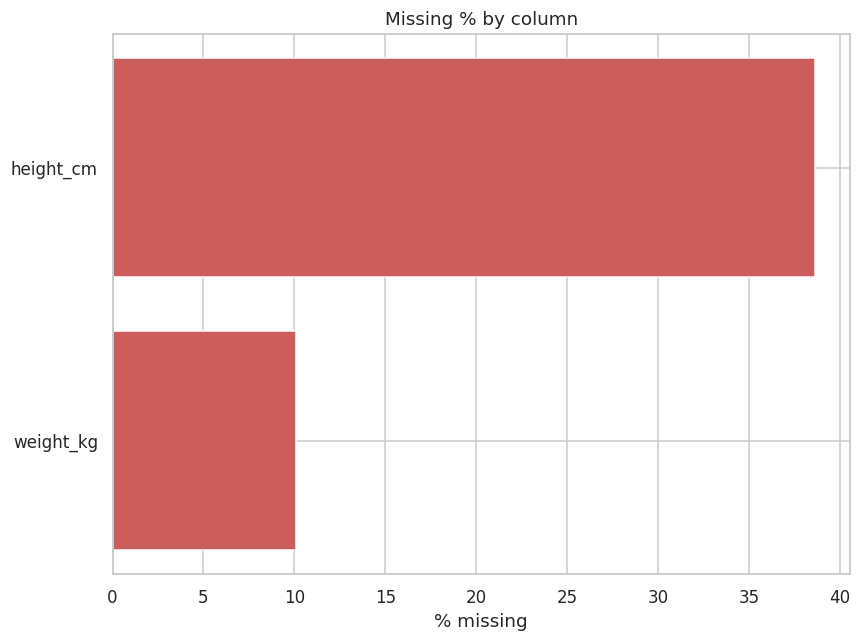

In [13]:
mt = missing_table(sub)
mt = mt[mt.missing_pct > 0]

plt.figure(figsize=(8, 6))
plt.barh(mt.index, mt.missing_pct, color="indianred")
plt.xlabel("% missing")
plt.title("Missing % by column")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Reading the missingness.** `height_cm` (~39%) and `weight_kg` (~10%) carry
the only substantial missingness.

In [14]:
# Quick MAR probe: is height-missingness associated with sex / ventilation?
for c in ["sex", "has_invasive_vent", "has_crrt"]:
    tab = pd.crosstab(cov_clean.height_cm.isna(), cov_clean[c])
    chi2, p, *_ = ss.chi2_contingency(tab)
    print(f"height-missing  vs  {c:20s}: chi2={chi2:8.2f}  p={p:.3e}  "
          f"-> {interpret_p(p)} (suggests {'MAR' if p<0.05 else 'MCAR-compatible'})")

height-missing  vs  sex                 : chi2=   10.57  p=1.152e-03  -> significant (suggests MAR)
height-missing  vs  has_invasive_vent   : chi2= 3360.13  p=0.000e+00  -> significant (suggests MAR)
height-missing  vs  has_crrt            : chi2=  345.06  p=5.038e-77  -> significant (suggests MAR)


### Outlier Analysis
IQR fences **and** robust (MAD-based) Z-scores for each numerical variable.
Boxplots + density plots. **Outliers are flagged, not removed.**

In [15]:
NUM_COV = ["age", "los_icu_hrs", "weight_kg", "height_cm"]
def outlier_summary(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    iqr_out = ((s < lo) | (s > hi)).sum()
    rz = robust_z(s.values)
    rz_out = (np.abs(rz) > 3.5).sum()
    return {"n": len(s), "iqr_lo": lo, "iqr_hi": hi,
            "iqr_outliers": iqr_out, "iqr_pct": round(100*iqr_out/len(s), 2),
            "robustZ_outliers(|z|>3.5)": rz_out,
            "robustZ_pct": round(100*rz_out/len(s), 2)}

display(pd.DataFrame({c: outlier_summary(cov_clean[c]) for c in NUM_COV}).T)

# also event values
ev_num = {"dose(mg)": dose.valuminum, "concentration(mg/L)": conc.valuenum}
display(pd.DataFrame({k: outlier_summary(v) for k, v in ev_num.items()}).T)

,n,iqr_lo,iqr_hi,iqr_outliers,iqr_pct,robustZ_outliers(|z|>3.5),robustZ_pct
age,"16,460.0000",21.5000,105.5000,119.0000,0.7200,0.0000,0.0000
los_icu_hrs,"16,460.0000",-224.1891,532.5195,"1,095.0000",6.6500,"1,257.0000",7.6400
weight_kg,"14,802.0000",21.6500,141.2500,438.0000,2.9600,251.0000,1.7000
height_cm,"10,104.0000",140.5000,200.5000,100.0000,0.9900,42.0000,0.4200


,n,iqr_lo,iqr_hi,iqr_outliers,iqr_pct,robustZ_outliers(|z|>3.5),robustZ_pct
dose(mg),"121,672.0000","1,000.0000","1,000.0000","40,035.0000",32.9000,0.0000,0.0000
concentration(mg/L),"83,094.0000",-0.8500,36.3500,"2,195.0000",2.6400,"1,099.0000",1.3200


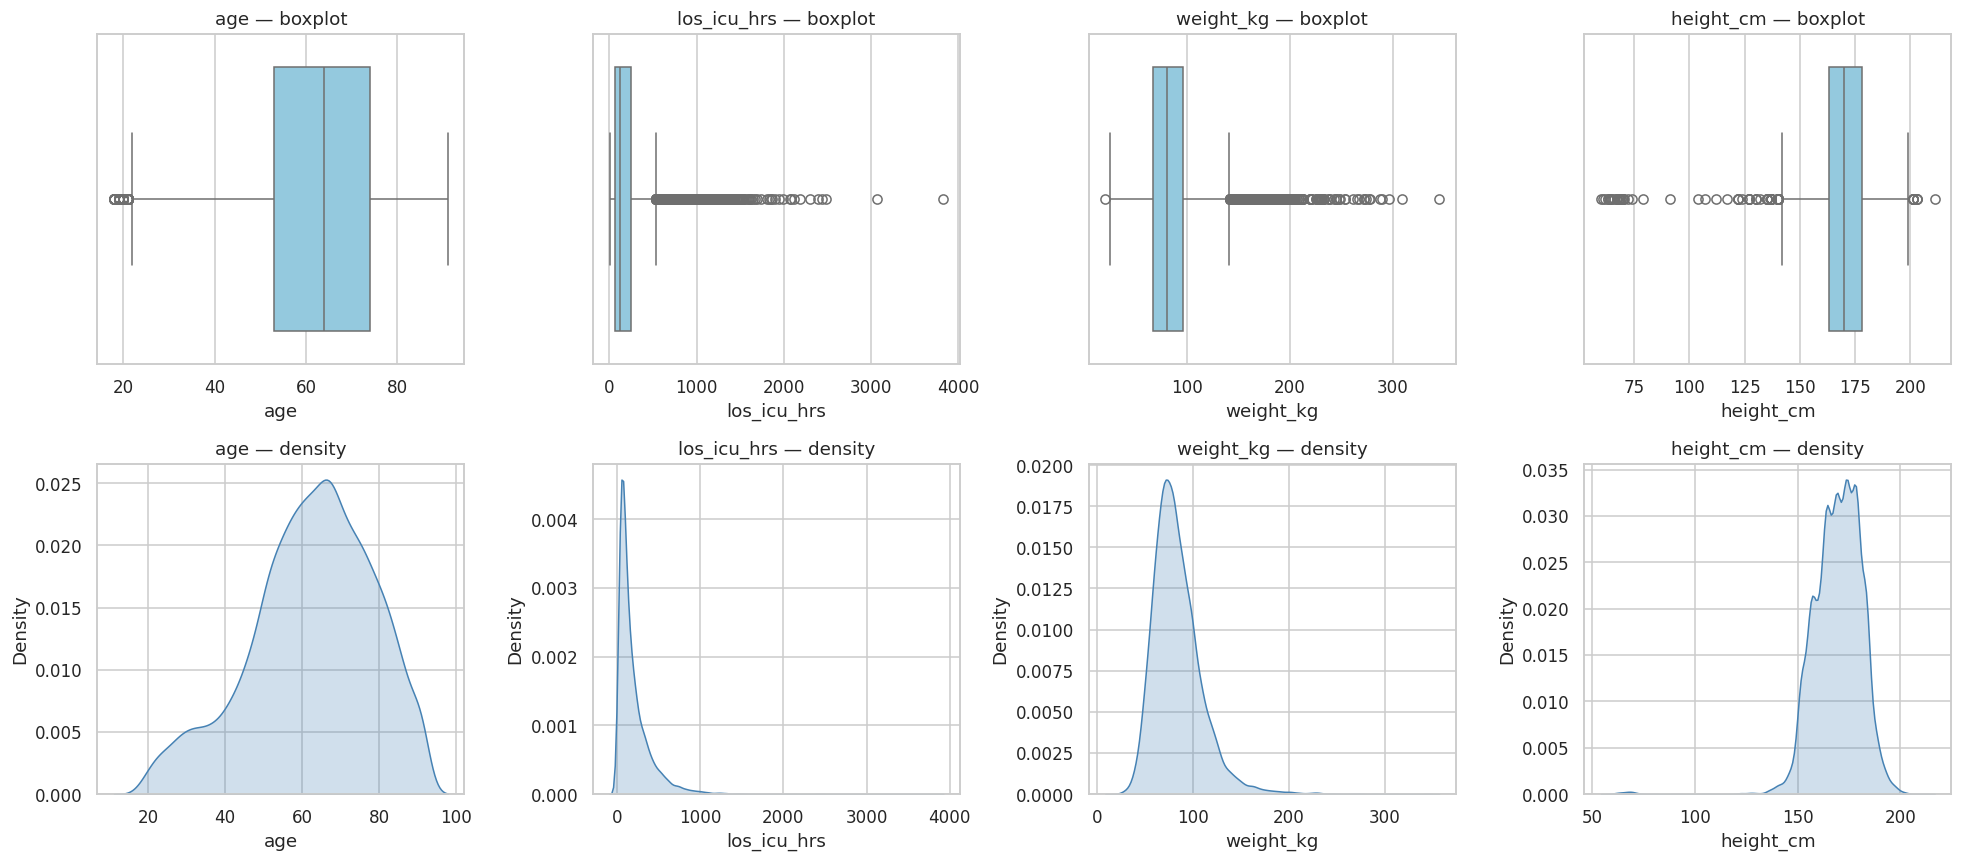

In [16]:
# Boxplots + density per covariate
fig, axes = plt.subplots(2, len(NUM_COV), figsize=(4.5*len(NUM_COV), 8))
for j, c in enumerate(NUM_COV):
    s = cov_clean[c].dropna()
    sns.boxplot(x=s, ax=axes[0, j], color="skyblue")
    axes[0, j].set_title(f"{c} — boxplot")
    sns.kdeplot(s, ax=axes[1, j], fill=True, color="steelblue")
    axes[1, j].set_title(f"{c} — density")
plt.tight_layout(); plt.show()

**Outlier impact discussion.** `los_icu_hrs` is heavily right-skewed (a few
multi-month stays) — expected in ICU data and clinically real, not error.
`weight_kg`/`height_cm` extremes after masking are mostly genuine bariatric or
data-entry edge cases. For PK modelling these influence volume-of-distribution
and clearance scaling; we recommend **robust / log-scale handling** rather than
deletion, since removal would bias the dosing model away from the very patients
(obese, long-stay, renal-support) where dosing is hardest.

## 5. Univariate Analysis

### Numerical variables — full descriptive battery

In [17]:
def describe_numeric(s):
    s = s.dropna()
    return pd.Series({
        "count": len(s), "mean": s.mean(), "median": s.median(),
        "mode": s.mode().iloc[0] if not s.mode().empty else np.nan,
        "std": s.std(), "variance": s.var(),
        "IQR": s.quantile(.75)-s.quantile(.25),
        "MAD": ss.median_abs_deviation(s),
        "skewness": ss.skew(s), "kurtosis": ss.kurtosis(s),
        "min": s.min(), "max": s.max(),
        "q01": s.quantile(.01), "q05": s.quantile(.05),
        "q25": s.quantile(.25), "q75": s.quantile(.75),
        "q95": s.quantile(.95), "q99": s.quantile(.99),
    })

num_vars = {**{c: cov_clean[c] for c in NUM_COV},
            "dose_mg": dose.valuminum, "concentration": conc.valuenum}
# add per-analyte labs
for et in [2, 3, 4, 5, 6]:
    num_vars[f"lab_{EVENT_LABELS[et]}"] = labs.loc[labs.event_type == et, "valuenum"]

desc = pd.DataFrame({k: describe_numeric(v) for k, v in num_vars.items()}).T
display(desc)

,count,mean,median,mode,std,variance,IQR,MAD,skewness,kurtosis,min,max,q01,q05,q25,q75,q95,q99
age,"16,460.0000",62.4403,64.0000,67.0000,15.9362,253.9632,21.0000,11.0000,-0.4450,-0.2263,18.0000,91.0000,23.0000,32.0000,53.0000,74.0000,86.0000,91.0000
los_icu_hrs,"16,460.0000",193.9533,120.1318,16.0169,213.8111,"45,715.1868",189.1772,73.9508,3.1761,19.1923,3.0975,"3,832.0033",16.1854,25.1617,59.5767,248.7538,596.9359,"1,027.4039"
weight_kg,"14,802.0000",83.8217,80.0000,80.0000,26.1537,684.0166,29.9000,14.7000,1.6985,6.7049,20.5000,345.0000,41.1020,50.8000,66.5000,96.4000,128.6000,172.0000
height_cm,"10,104.0000",169.2570,170.0000,178.0000,12.0254,144.6101,15.0000,8.0000,-1.8094,13.1777,60.0000,211.0000,142.0000,152.0000,163.0000,178.0000,185.0000,193.0000
dose_mg,"121,672.0000","1,055.5609","1,000.0000","1,000.0000",226.0773,"51,110.9264",0.0000,0.0000,0.8042,1.9235,100.0000,"2,000.0000",500.0000,750.0000,"1,000.0000","1,000.0000","1,500.0000","1,750.0000"
concentration,"83,094.0000",18.4018,17.6000,15.0000,8.2821,68.5925,9.3000,4.6000,2.8887,50.4716,0.0000,352.5000,4.2000,7.2000,13.1000,22.4000,32.0000,43.8000
lab_Creatinine,"248,383.0000",1.6900,1.2000,0.7000,1.5040,2.2621,1.4000,0.6000,3.1750,40.9721,0.1000,80.0000,0.3000,0.4000,0.7000,2.1000,4.7000,7.4000
lab_BUN,"248,014.0000",36.4215,28.0000,14.0000,27.5800,760.6541,31.0000,14.0000,1.7140,4.0921,1.0000,305.0000,5.0000,8.0000,17.0000,48.0000,93.0000,131.0000
lab_Albumin,"36,245.0000",2.7759,2.7000,2.8000,0.6234,0.3886,0.9000,0.4000,0.4311,0.6213,0.3000,6.6000,1.5000,1.8000,2.3000,3.2000,3.9000,4.4000
lab_ALT,"75,319.0000",217.2073,43.0000,17.0000,738.4635,"545,328.3591",89.0000,28.0000,15.7617,767.1130,1.0000,"61,854.0000",6.0000,9.0000,21.0000,110.0000,974.0000,"3,369.4600"


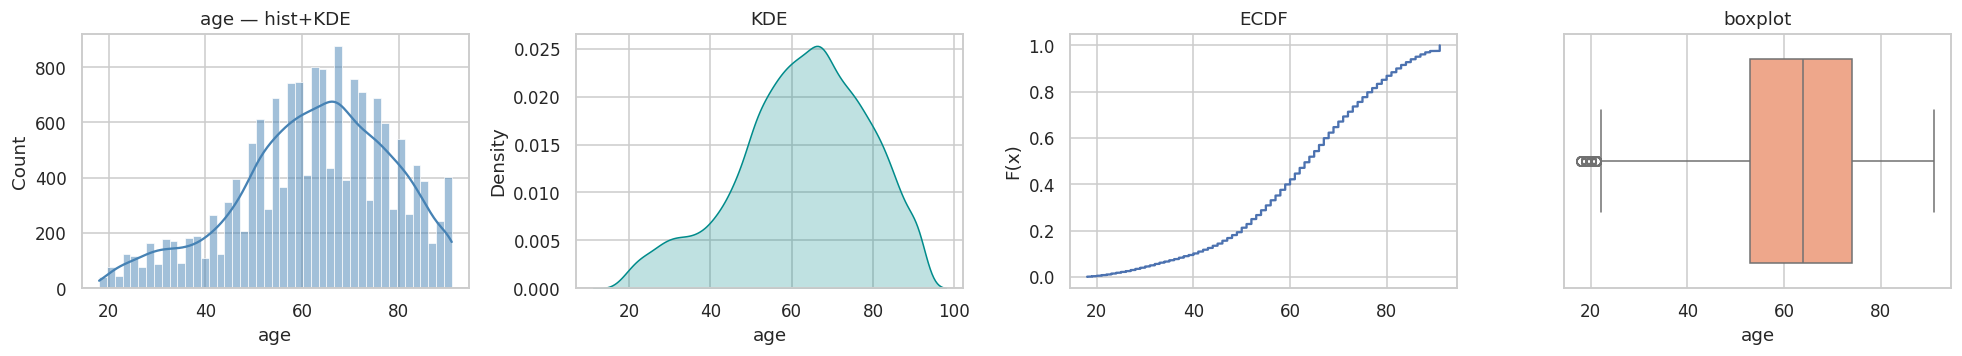

age: skew=-0.44 (approximately symmetric), excess-kurtosis=-0.23 (meso-kurtic)


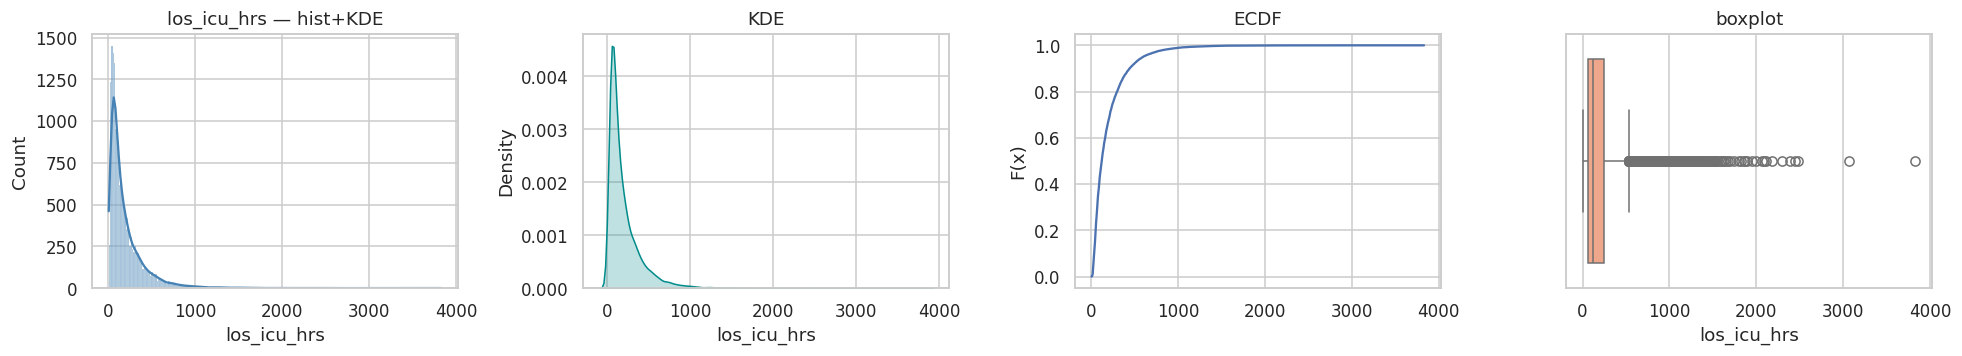

los_icu_hrs: skew=3.18 (right-skewed), excess-kurtosis=19.19 (heavy-tailed)


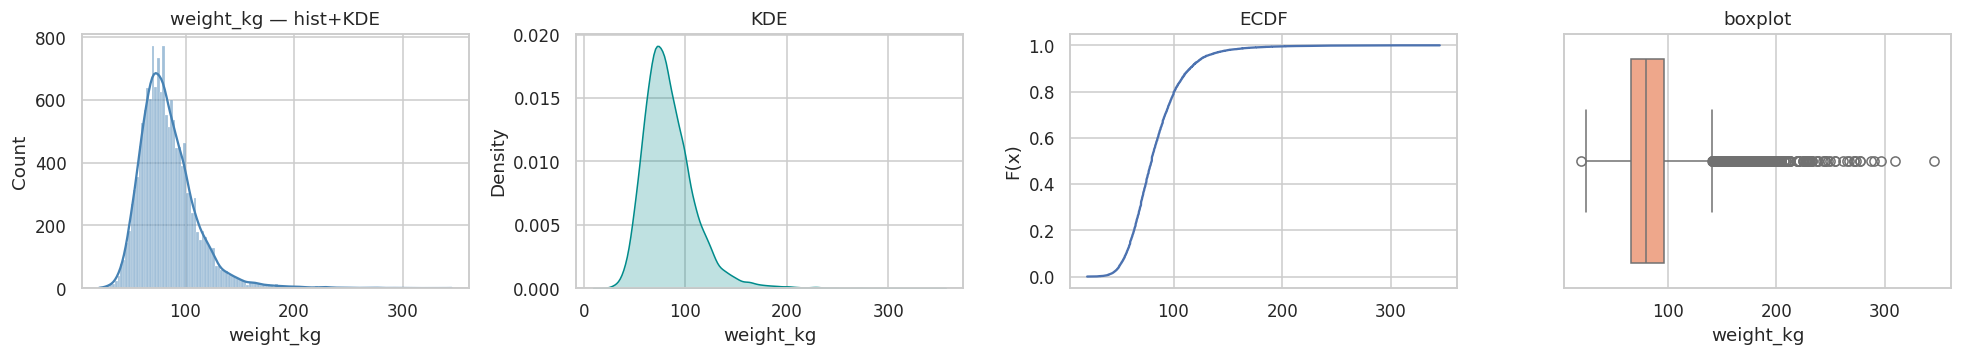

weight_kg: skew=1.70 (right-skewed), excess-kurtosis=6.70 (heavy-tailed)


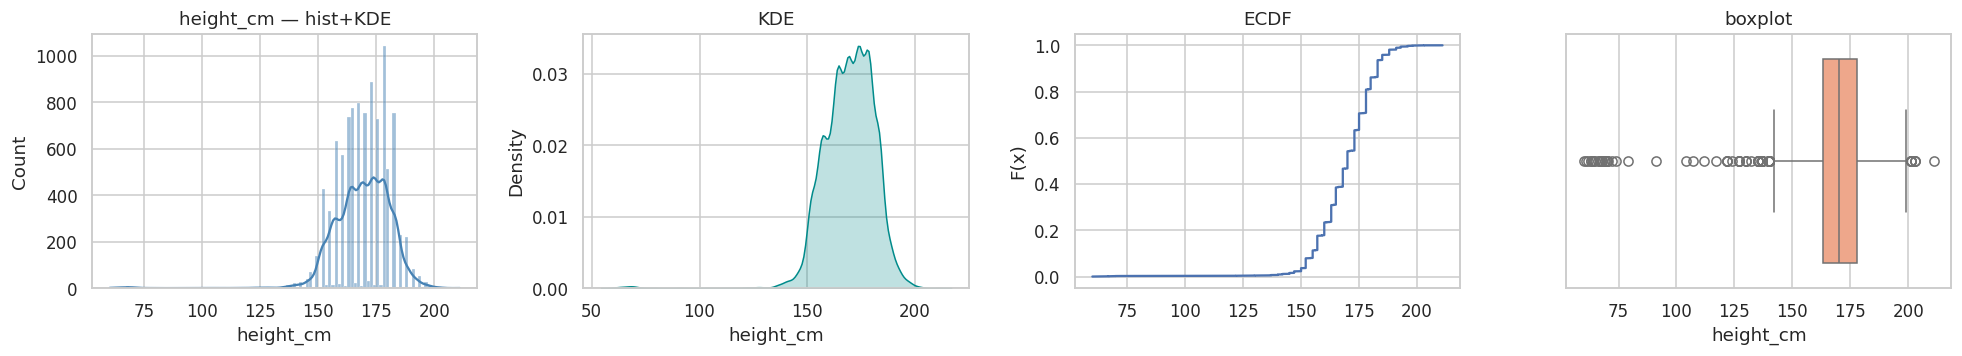

height_cm: skew=-1.81 (left-skewed), excess-kurtosis=13.18 (heavy-tailed)


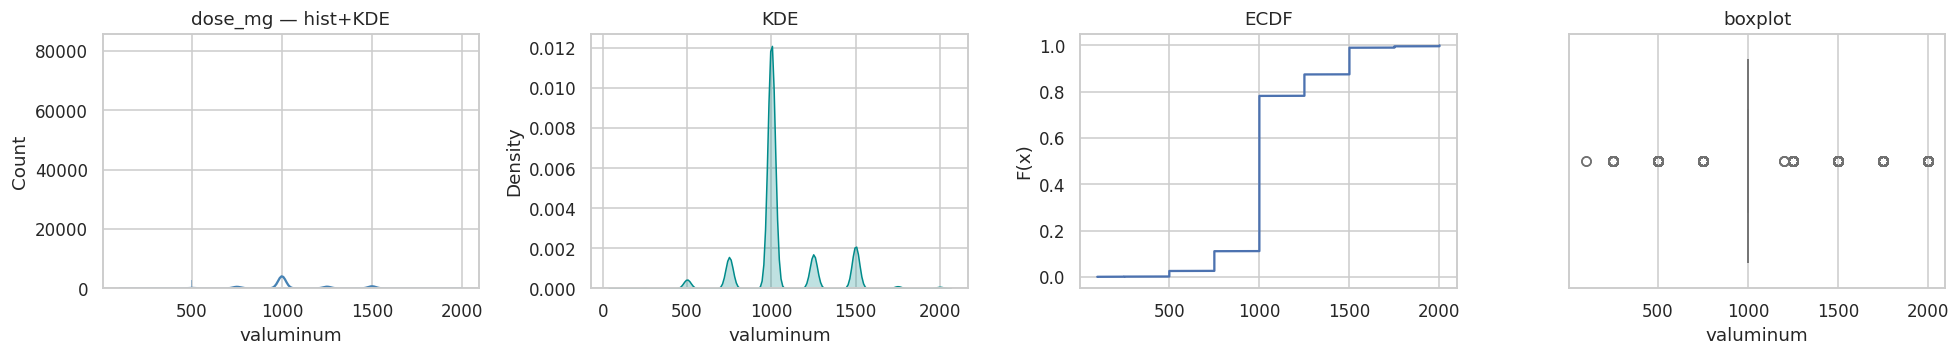

dose_mg: skew=0.80 (right-skewed), excess-kurtosis=1.92 (heavy-tailed)


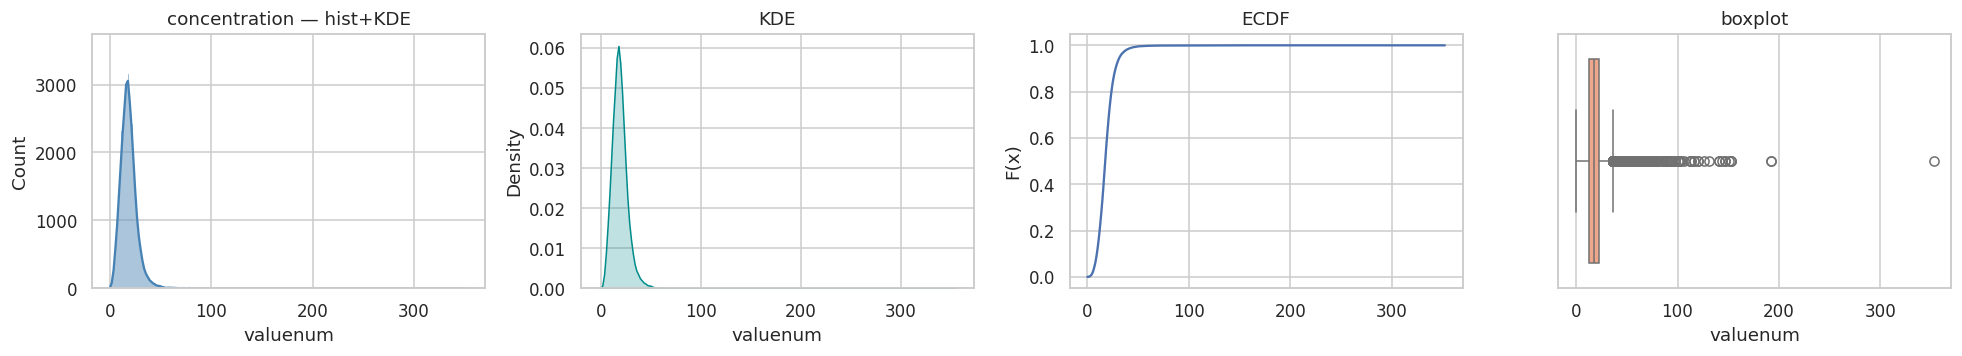

concentration: skew=2.89 (right-skewed), excess-kurtosis=50.47 (heavy-tailed)


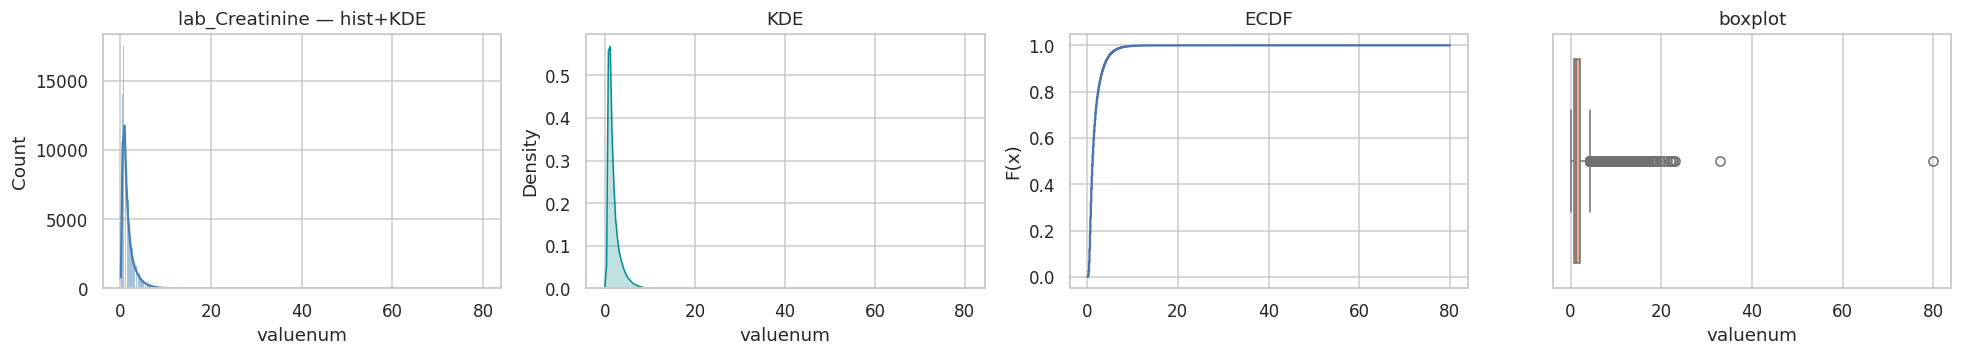

lab_Creatinine: skew=3.17 (right-skewed), excess-kurtosis=40.97 (heavy-tailed)


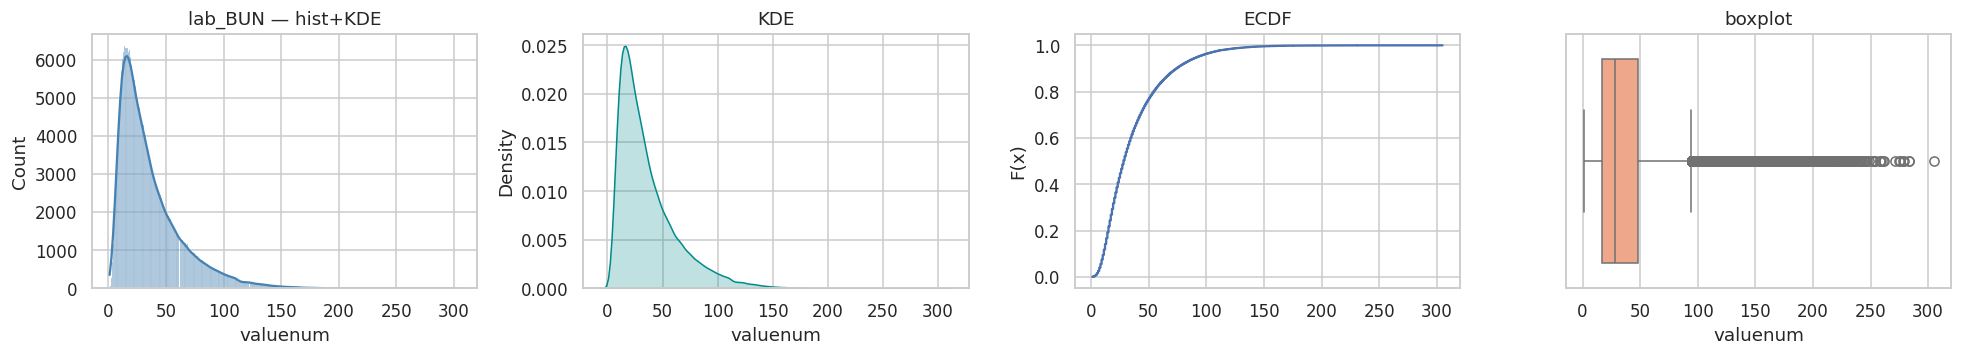

lab_BUN: skew=1.71 (right-skewed), excess-kurtosis=4.09 (heavy-tailed)


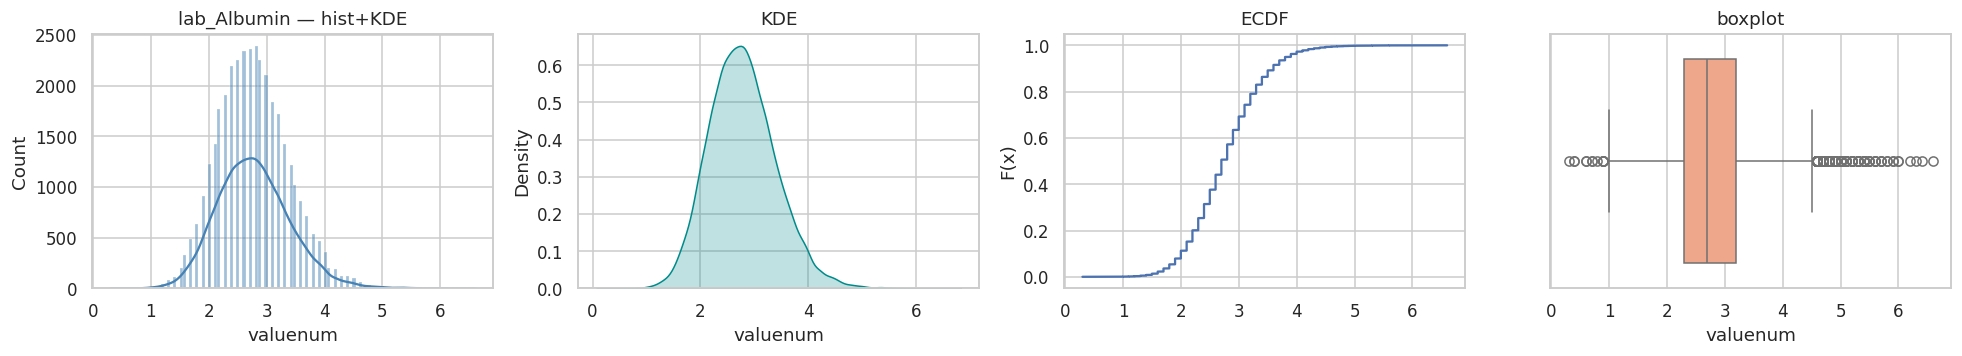

lab_Albumin: skew=0.43 (approximately symmetric), excess-kurtosis=0.62 (meso-kurtic)


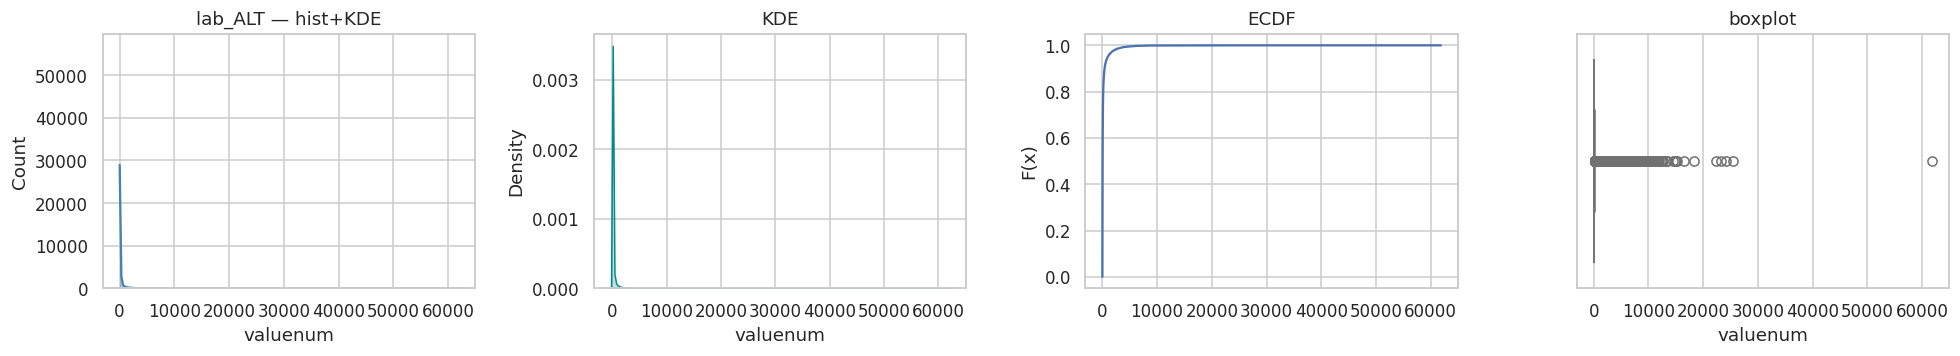

lab_ALT: skew=15.76 (right-skewed), excess-kurtosis=767.11 (heavy-tailed)


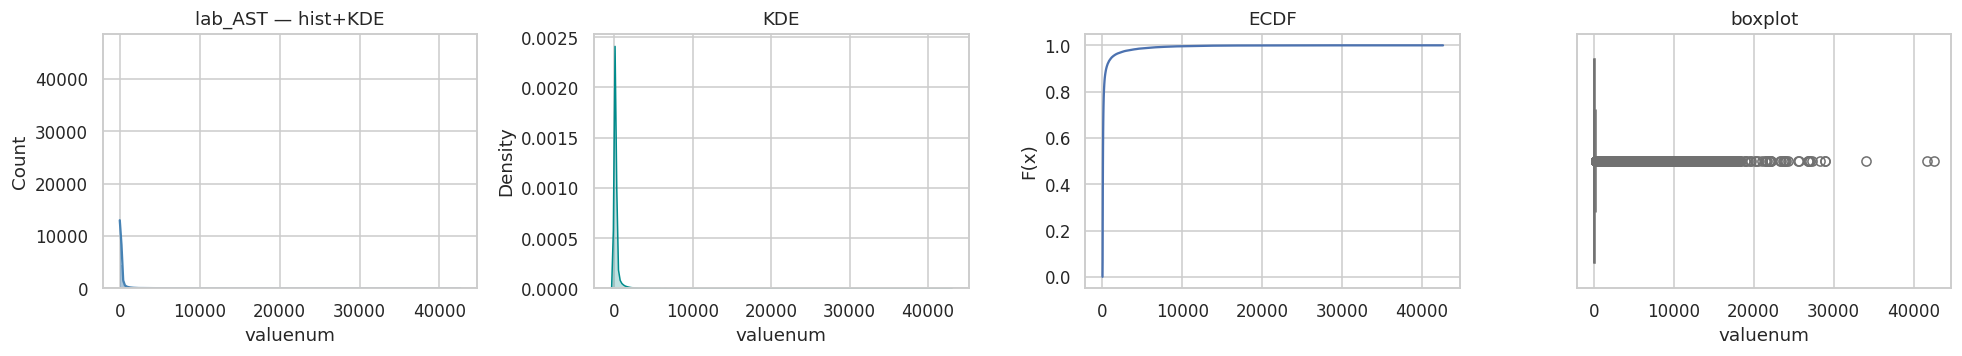

lab_AST: skew=10.00 (right-skewed), excess-kurtosis=150.38 (heavy-tailed)


In [18]:
# Histogram + KDE + ECDF + boxplot for each numerical variable
for name, s in num_vars.items():
    s = s.dropna()
    if len(s) == 0:
        continue
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.4))
    sns.histplot(s, kde=True, ax=ax[0], color="steelblue")
    ax[0].set_title(f"{name} — hist+KDE")
    sns.kdeplot(s, ax=ax[1], fill=True, color="darkcyan"); ax[1].set_title("KDE")
    xs = np.sort(s.values); ax[2].plot(xs, np.arange(1, len(xs)+1)/len(xs))
    ax[2].set_title("ECDF"); ax[2].set_ylabel("F(x)")
    sns.boxplot(x=s, ax=ax[3], color="lightsalmon"); ax[3].set_title("boxplot")
    plt.tight_layout(); plt.show()
    sk, ku = ss.skew(s), ss.kurtosis(s)
    shape = ("right-skewed" if sk > 0.5 else "left-skewed" if sk < -0.5
             else "approximately symmetric")
    tail = ("heavy-tailed" if ku > 1 else "light-tailed" if ku < -1 else "meso-kurtic")
    print(f"{name}: skew={sk:.2f} ({shape}), excess-kurtosis={ku:.2f} ({tail})")

### Categorical variables — frequency, cardinality, rare categories

In [19]:
CAT_VARS = ["sex", "has_invasive_vent", "has_non_invasive_vent", "has_hd",
            "has_crrt", "has_pd", "has_other_dialysis", "has_vasopressor"]
for c in CAT_VARS:
    vc = cov[c].value_counts(dropna=False)
    rel = (vc/len(cov)).round(4)
    tab = pd.DataFrame({"frequency": vc, "relative": rel})
    print(f"\n{c}  | cardinality={cov[c].nunique(dropna=False)}")
    display(tab)
    rare = rel[rel < 0.05]
    if len(rare):
        print("  rare categories (<5%):", rare.index.tolist())


sex  | cardinality=2


,frequency,relative
sex,,
M,9774,0.5938
F,6686,0.4062



has_invasive_vent  | cardinality=2


,frequency,relative
has_invasive_vent,,
1,10101,0.6137
0,6359,0.3863



has_non_invasive_vent  | cardinality=2


...

,frequency,relative
has_pd,,
0,16411,0.9970
1,49,0.0030


  rare categories (<5%): [1]

has_other_dialysis  | cardinality=1


,frequency,relative
has_other_dialysis,,
0,16460,1.0000



has_vasopressor  | cardinality=2


,frequency,relative
has_vasopressor,,
0,10228,0.6214
1,6232,0.3786


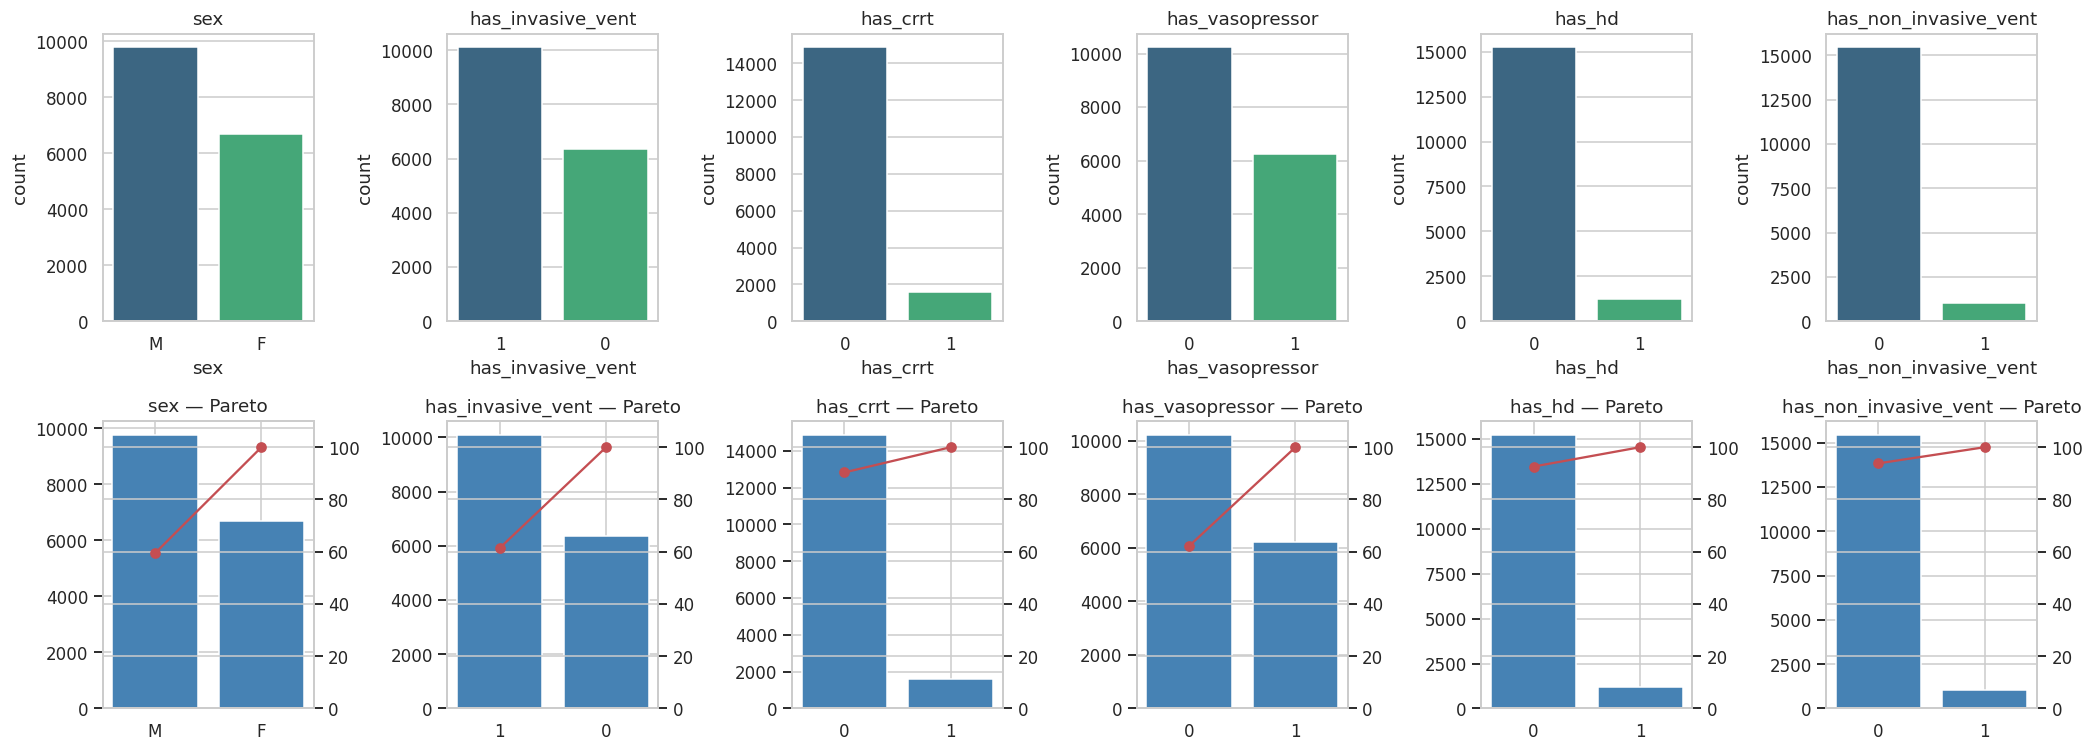

In [20]:
# Count plots + Pareto for the informative categoricals
plot_cats = ["sex", "has_invasive_vent", "has_crrt", "has_vasopressor",
             "has_hd", "has_non_invasive_vent"]
fig, axes = plt.subplots(2, len(plot_cats), figsize=(3.2*len(plot_cats), 7))
for j, c in enumerate(plot_cats):
    vc = cov[c].value_counts()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=axes[0, j], palette="viridis")
    axes[0, j].set_title(c); axes[0, j].set_ylabel("count")
    # Pareto
    cum = vc.cumsum()/vc.sum()*100
    axes[1, j].bar(vc.index.astype(str), vc.values, color="steelblue")
    ax2 = axes[1, j].twinx(); ax2.plot(vc.index.astype(str), cum.values,
                                       "ro-"); ax2.set_ylim(0, 110)
    axes[1, j].set_title(f"{c} — Pareto")
plt.tight_layout(); plt.show()

## 6. Distribution Diagnostics
Shapiro–Wilk (sub-sampled to ≤5000 as required by the test) **and**
D'Agostino–Pearson, plus QQ/PP plots, with transformation recommendations.

In [21]:
def normality_block(s, name):
    s = s.dropna().values
    n = len(s)
    samp = s if n <= 5000 else RNG.choice(s, 5000, replace=False)
    sw_W, sw_p = ss.shapiro(samp)
    dp_stat, dp_p = ss.normaltest(s)
    sk, ku = ss.skew(s), ss.kurtosis(s)
    rec = "none"
    if sk > 1:
        rec = "log / Box-Cox (all-positive) — strong right skew"
    elif sk > 0.5:
        rec = "sqrt / Yeo-Johnson"
    elif sk < -0.5:
        rec = "Yeo-Johnson (handles negatives)"
    return {"n": n, "shapiro_W": sw_W, "shapiro_p": sw_p,
            "dagostino_stat": dp_stat, "dagostino_p": dp_p,
            "skew": sk, "kurtosis": ku, "transform_reco": rec}

cont_vars = {k: v for k, v in num_vars.items()}
nrm = pd.DataFrame({k: normality_block(v, k) for k, v in cont_vars.items()}).T
display(nrm)
print("Both tests reject normality (p<<0.05) for essentially all PK variables — "
      "expected: concentrations and labs are log-normal, LOS is exponential-like.")

,n,shapiro_W,shapiro_p,dagostino_stat,dagostino_p,skew,kurtosis,transform_reco
age,16460,0.9791,0.0000,541.6400,0.0000,-0.4450,-0.2263,none
los_icu_hrs,16460,0.7219,0.0000,"11,774.0202",0.0000,3.1761,19.1923,log / Box-Cox (all-positive) — strong right skew
weight_kg,14802,0.9018,0.0000,"5,616.4097",0.0000,1.6985,6.7049,log / Box-Cox (all-positive) — strong right skew
height_cm,10104,0.9040,0.0000,"4,699.5189",0.0000,-1.8094,13.1777,Yeo-Johnson (handles negatives)
dose_mg,121672,0.7633,0.0000,"15,631.0389",0.0000,0.8042,1.9235,sqrt / Yeo-Johnson
concentration,83094,0.9108,0.0000,"63,603.0386",0.0000,2.8887,50.4716,log / Box-Cox (all-positive) — strong right skew
lab_Creatinine,248383,0.7313,0.0000,"195,486.0137",0.0000,3.1750,40.9721,log / Box-Cox (all-positive) — strong right skew
lab_BUN,248014,0.8514,0.0000,"84,037.4111",0.0000,1.7140,4.0921,log / Box-Cox (all-positive) — strong right skew
lab_Albumin,36245,0.9874,0.0000,"1,379.4748",0.0000,0.4311,0.6213,none
lab_ALT,75319,0.2794,0.0000,"150,703.0320",0.0000,15.7617,767.1130,log / Box-Cox (all-positive) — strong right skew


Both tests reject normality (p<<0.05) for essentially all PK variables — expected: concentrations and labs are log-normal, LOS is exponential-like.


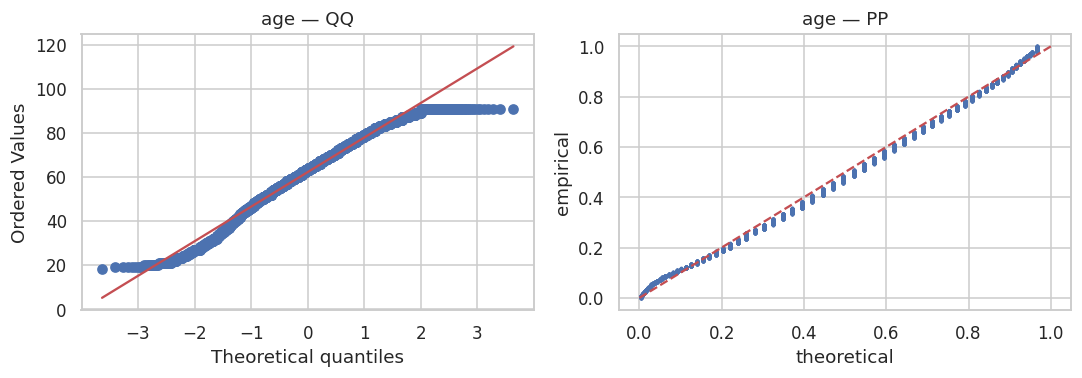

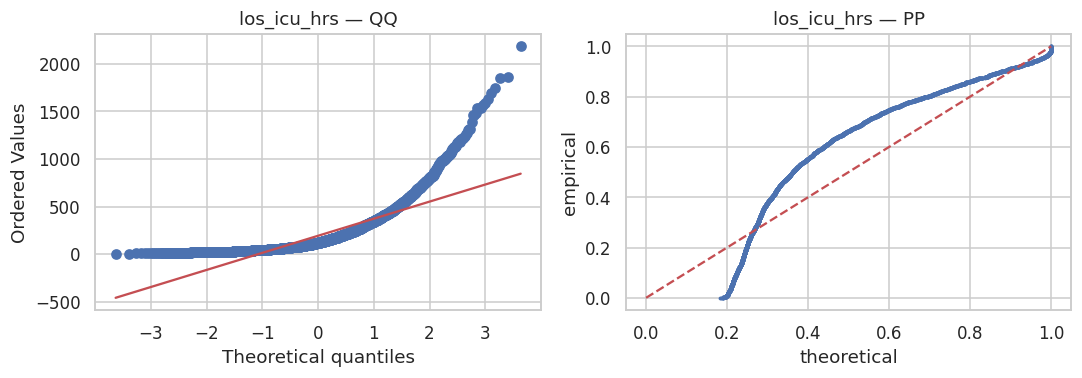

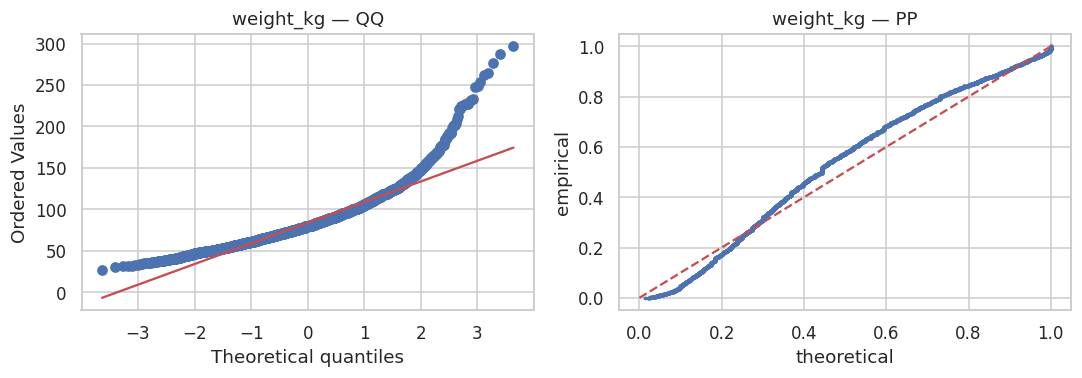

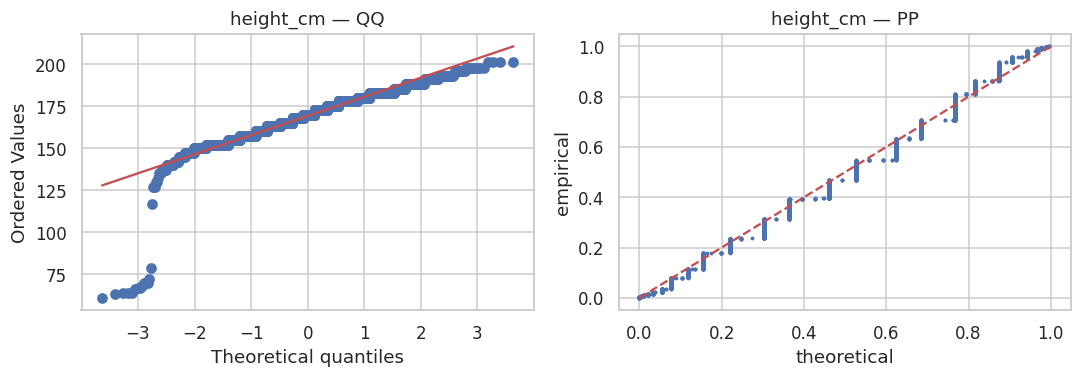

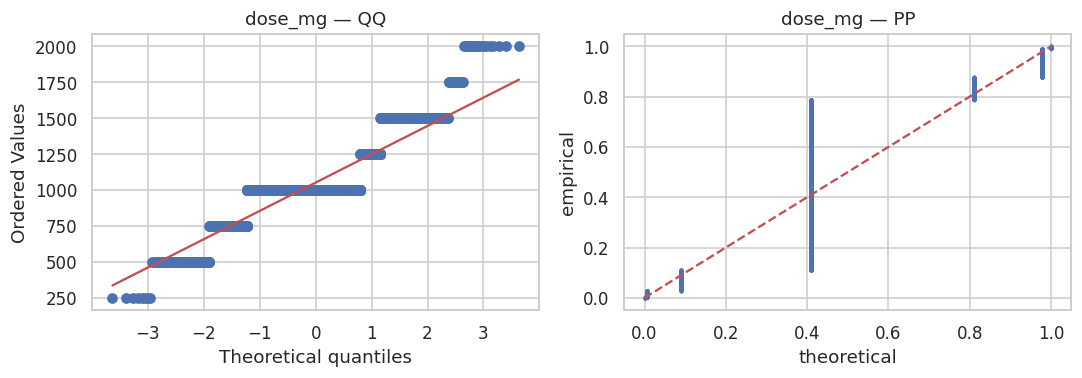

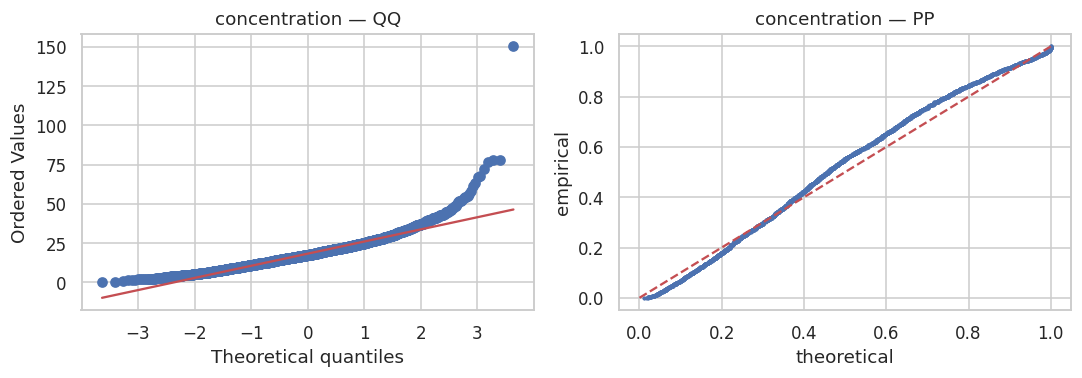

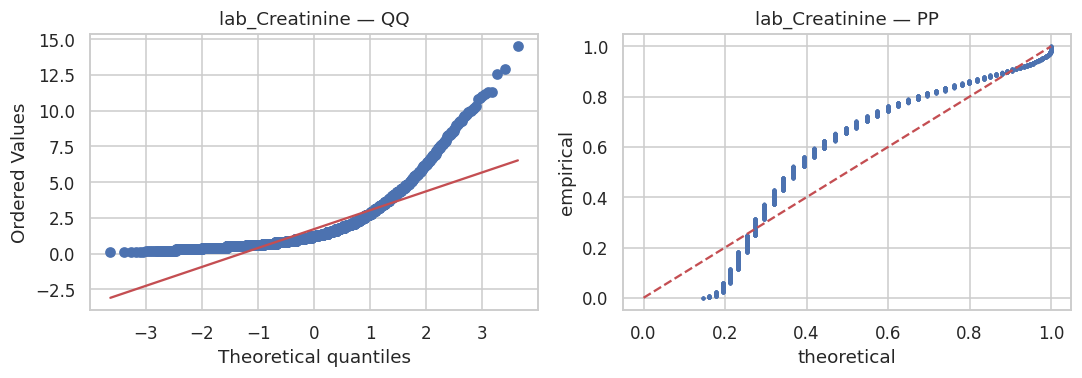

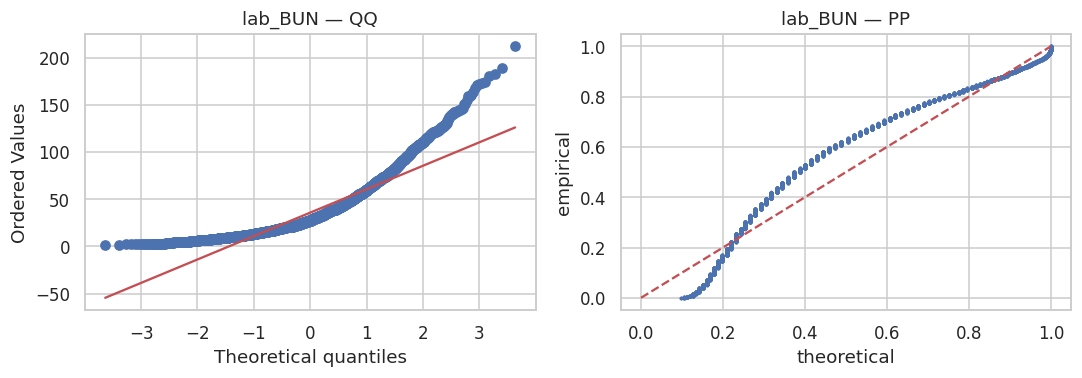

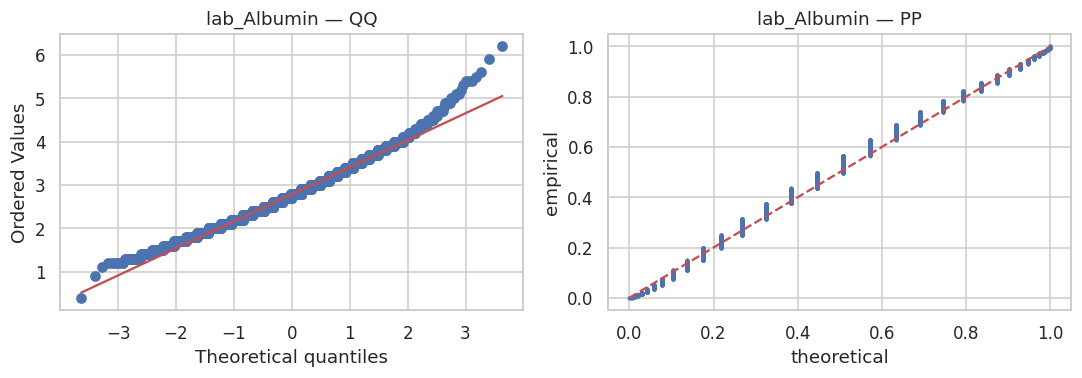

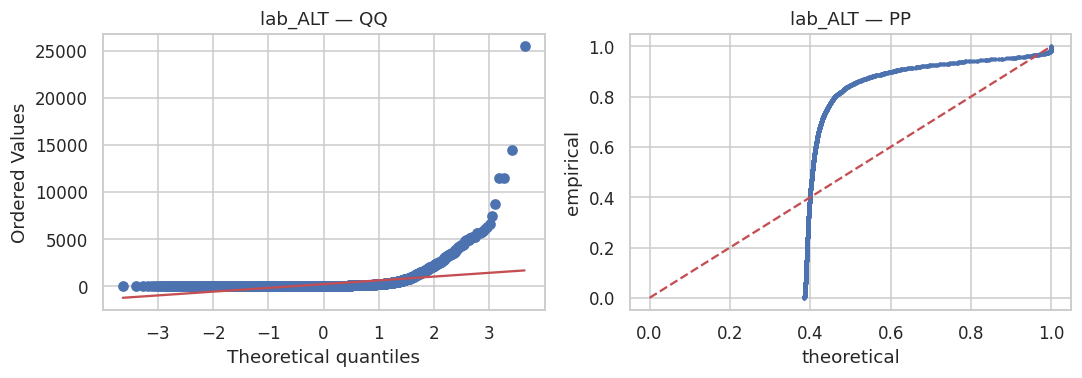

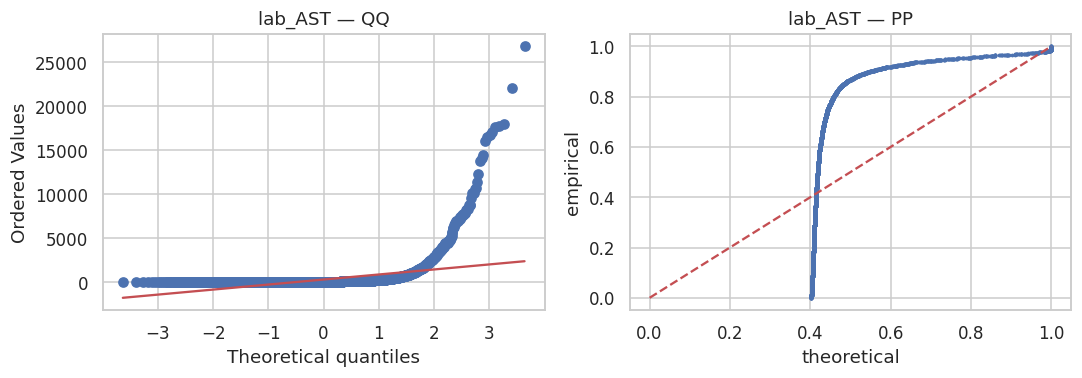

In [22]:
# QQ + PP plots
for name, s in cont_vars.items():
    s = s.dropna().values
    if len(s) < 8:
        continue
    samp = s if len(s) <= 5000 else RNG.choice(s, 5000, replace=False)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ss.probplot(samp, dist="norm", plot=ax[0]); ax[0].set_title(f"{name} — QQ")
    # PP plot
    z = np.sort((samp - samp.mean())/samp.std())
    emp = np.arange(1, len(z)+1)/len(z)
    theo = ss.norm.cdf(z)
    ax[1].plot(theo, emp, ".", ms=3); ax[1].plot([0, 1], [0, 1], "r--")
    ax[1].set_title(f"{name} — PP"); ax[1].set_xlabel("theoretical")
    ax[1].set_ylabel("empirical")
    plt.tight_layout(); plt.show()

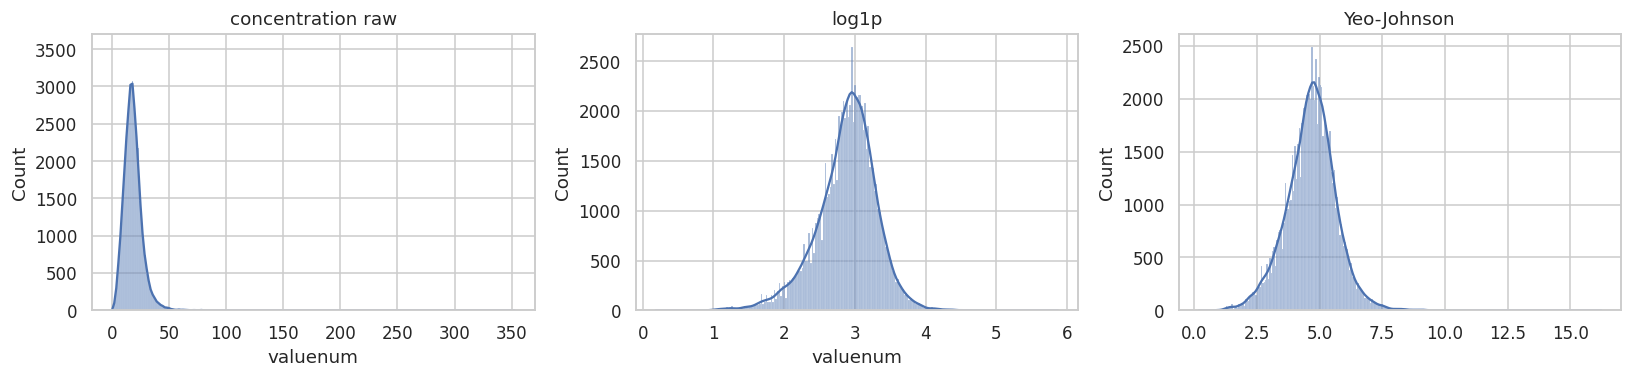

log1p brings concentration close to symmetric — supports modelling on the log scale.


In [23]:
# Demonstrate recommended transforms on the worst-skewed PK variable
demo = conc.valuenum.dropna()
demo = demo[demo > 0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(demo, kde=True, ax=ax[0]); ax[0].set_title("concentration raw")
sns.histplot(np.log1p(demo), kde=True, ax=ax[1]); ax[1].set_title("log1p")
yj, _ = ss.yeojohnson(demo.values)
sns.histplot(yj, kde=True, ax=ax[2]); ax[2].set_title("Yeo-Johnson")
plt.tight_layout(); plt.show()
print("log1p brings concentration close to symmetric — supports modelling on "
      "the log scale.")

## 7. Bivariate Analysis
#
To relate the long event tables to per-stay covariates we build a **per-stay
feature frame**: median concentration, total dose, last creatinine, etc.

In [24]:
def per_stay(df, val, agg, prefix):
    g = df.groupby("stay_id")[val].agg(agg)
    g.columns = [f"{prefix}_{a}" for a in agg]
    return g

stay = cov_clean.set_index("stay_id").copy()
stay = stay.join(per_stay(conc, "valuenum", ["median", "max", "count"], "conc"))
stay = stay.join(per_stay(dose, "valuminum", ["sum", "mean", "count"], "dose"))
for et in [2, 3, 4]:
    g = labs[labs.event_type == et].groupby("stay_id")["valuenum"].median()
    stay[f"lab_{EVENT_LABELS[et]}_med"] = g
stay = stay.reset_index()
print("Per-stay analytic frame:", stay.shape)
display(stay.head())

Per-stay analytic frame: (16460, 26)


,stay_id,subject_id,hadm_id,age,sex,los_icu_hrs,intime,outtime,weight_kg,height_cm,has_invasive_vent,has_non_invasive_vent,has_hd,has_crrt,has_pd,has_other_dialysis,has_vasopressor,conc_median,conc_max,conc_count,dose_sum,dose_mean,dose_count,lab_Creatinine_med,lab_BUN_med,lab_Albumin_med
0,37330124,16650418,25388051,76,M,167.4450,2147-06-07 19:30:00,2147-06-14 18:56:42,73.0000,175.0000,1,1,0,0,0,0,0,11.4000,11.4000,1,"7,000.0000",777.7778,9,1.7000,55.5000,2.6000
1,39009171,16651008,24652180,40,F,26.3178,2145-09-09 22:52:00,2145-09-11 01:11:04,105.0000,NaN,0,0,1,0,0,0,0,12.6000,20.2000,3,"1,000.0000","1,000.0000",1,6.3000,56.5000,NaN
2,30290653,16652060,26645556,77,M,358.9361,2189-02-06 23:33:00,2189-02-21 22:29:10,66.4000,180.0000,1,1,0,0,0,0,1,31.4500,35.6000,4,"10,000.0000","1,000.0000",10,1.2000,33.0000,3.4500
3,35855170,16652205,28093183,85,M,478.5789,2169-03-12 23:14:02,2169-04-01 21:48:46,82.4000,NaN,1,0,0,0,0,0,1,11.2000,16.8000,2,"15,000.0000","1,000.0000",15,0.6000,21.5000,3.3000
4,35105595,16654740,29903568,50,M,342.7925,2134-03-28 19:22:10,2134-04-12 02:09:43,126.2000,140.0000,1,0,0,0,0,0,1,19.8000,34.0000,6,"7,500.0000","1,500.0000",5,1.1000,52.0000,NaN


### Numerical vs Numerical
Scatter / regression / joint plots and Pearson, Spearman, Kendall correlations
with bootstrap CIs.


Pearson correlation matrix:


,age,weight_kg,height_cm,los_icu_hrs,conc_median,dose_sum,lab_Creatinine_med,lab_BUN_med
age,1.0000,-0.1700,-0.1230,-0.0460,0.0650,-0.2190,0.0410,0.2210
weight_kg,-0.1700,1.0000,0.3430,0.0670,0.0280,0.1500,0.1070,0.1070
height_cm,-0.1230,0.3430,1.0000,0.0090,-0.0360,0.1090,0.0900,0.0620
los_icu_hrs,-0.0460,0.0670,0.0090,1.0000,0.0210,0.5030,-0.0460,0.0630
conc_median,0.0650,0.0280,-0.0360,0.0210,1.0000,-0.0060,0.0960,0.1530
dose_sum,-0.2190,0.1500,0.1090,0.5030,-0.0060,1.0000,-0.2690,-0.2130
lab_Creatinine_med,0.0410,0.1070,0.0900,-0.0460,0.0960,-0.2690,1.0000,0.6050
lab_BUN_med,0.2210,0.1070,0.0620,0.0630,0.1530,-0.2130,0.6050,1.0000



Spearman correlation matrix:


,age,weight_kg,height_cm,los_icu_hrs,conc_median,dose_sum,lab_Creatinine_med,lab_BUN_med
age,1.0000,-0.1710,-0.1400,-0.0340,0.0630,-0.2050,0.1400,0.2680
weight_kg,-0.1710,1.0000,0.4260,0.0600,0.0230,0.1760,0.1960,0.1340
height_cm,-0.1400,0.4260,1.0000,-0.0030,-0.0410,0.1180,0.1330,0.0780
los_icu_hrs,-0.0340,0.0600,-0.0030,1.0000,0.0560,0.5670,-0.0300,0.1190
conc_median,0.0630,0.0230,-0.0410,0.0560,1.0000,0.0340,0.1760,0.2040
dose_sum,-0.2050,0.1760,0.1180,0.5670,0.0340,1.0000,-0.4290,-0.3000
lab_Creatinine_med,0.1400,0.1960,0.1330,-0.0300,0.1760,-0.4290,1.0000,0.7480
lab_BUN_med,0.2680,0.1340,0.0780,0.1190,0.2040,-0.3000,0.7480,1.0000



Kendall correlation matrix:


,age,weight_kg,height_cm,los_icu_hrs,conc_median,dose_sum,lab_Creatinine_med,lab_BUN_med
age,1.0000,-0.1170,-0.0970,-0.0230,0.0420,-0.1420,0.0950,0.1820
weight_kg,-0.1170,1.0000,0.3040,0.0400,0.0150,0.1200,0.1340,0.0900
height_cm,-0.0970,0.3040,1.0000,-0.0020,-0.0280,0.0830,0.0930,0.0540
los_icu_hrs,-0.0230,0.0400,-0.0020,1.0000,0.0370,0.4060,-0.0200,0.0790
conc_median,0.0420,0.0150,-0.0280,0.0370,1.0000,0.0220,0.1180,0.1380
dose_sum,-0.1420,0.1200,0.0830,0.4060,0.0220,1.0000,-0.3040,-0.2050
lab_Creatinine_med,0.0950,0.1340,0.0930,-0.0200,0.1180,-0.3040,1.0000,0.5570
lab_BUN_med,0.1820,0.0900,0.0540,0.0790,0.1380,-0.2050,0.5570,1.0000


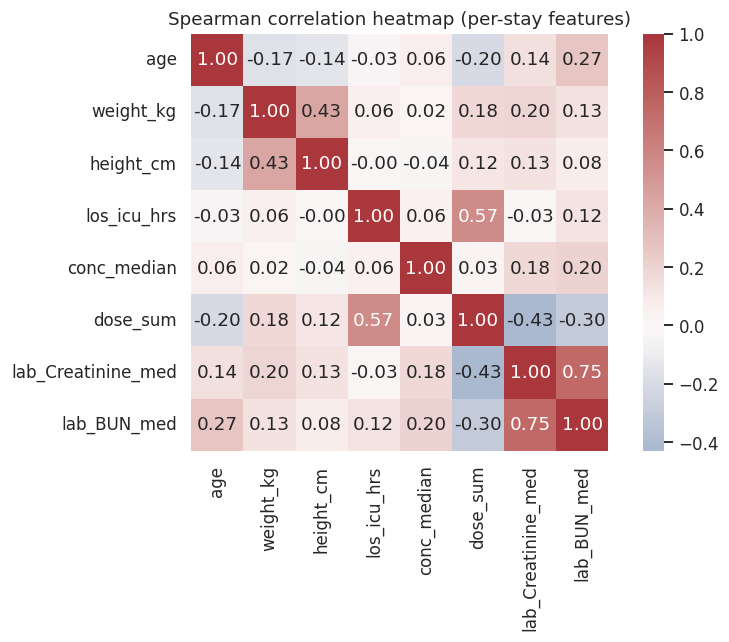

In [25]:
NN = ["age", "weight_kg", "height_cm", "los_icu_hrs",
      "conc_median", "dose_sum", "lab_Creatinine_med", "lab_BUN_med"]
NN = [c for c in NN if c in stay.columns]
M = stay[NN].dropna()

for method, fn in [("pearson", ss.pearsonr), ("spearman", ss.spearmanr),
                   ("kendall", ss.kendalltau)]:
    print(f"\n{method.title()} correlation matrix:")
    display(M.corr(method=method).round(3))

# correlation heatmap (Spearman — robust to the skew we documented)
plt.figure(figsize=(8, 6))
sns.heatmap(M.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag",
            center=0, square=True)
plt.title("Spearman correlation heatmap (per-stay features)")
plt.tight_layout(); plt.show()

Creatinine_med vs Conc_median:
  Pearson r=0.096 95% CI[0.076,0.116] p=2.32e-21 (significant)
  Spearman rho=0.176 p=8.44e-69


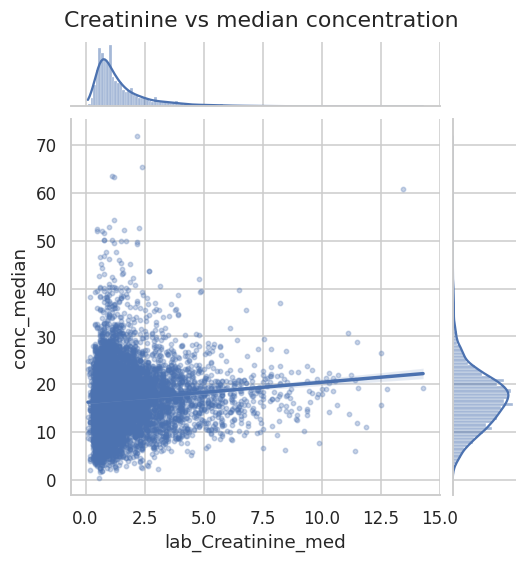

In [26]:
# Headline relationship with CI: creatinine vs concentration (renal clearance)
if {"lab_Creatinine_med", "conc_median"}.issubset(M.columns):
    a = M["lab_Creatinine_med"]; b = M["conc_median"]
    r, p = ss.pearsonr(a, b); rho, pr = ss.spearmanr(a, b)
    # Fisher-z CI for Pearson r
    z = np.arctanh(r); se = 1/np.sqrt(len(a)-3)
    ci = np.tanh([z-1.96*se, z+1.96*se])
    print(f"Creatinine_med vs Conc_median:\n  Pearson r={r:.3f} "
          f"95% CI[{ci[0]:.3f},{ci[1]:.3f}] p={p:.2e} ({interpret_p(p)})")
    print(f"  Spearman rho={rho:.3f} p={pr:.2e}")
    sns.jointplot(x=a, y=b, kind="reg", height=5,
                  joint_kws={"scatter_kws": {"s": 8, "alpha": .3}})
    plt.suptitle("Creatinine vs median concentration", y=1.02); plt.show()

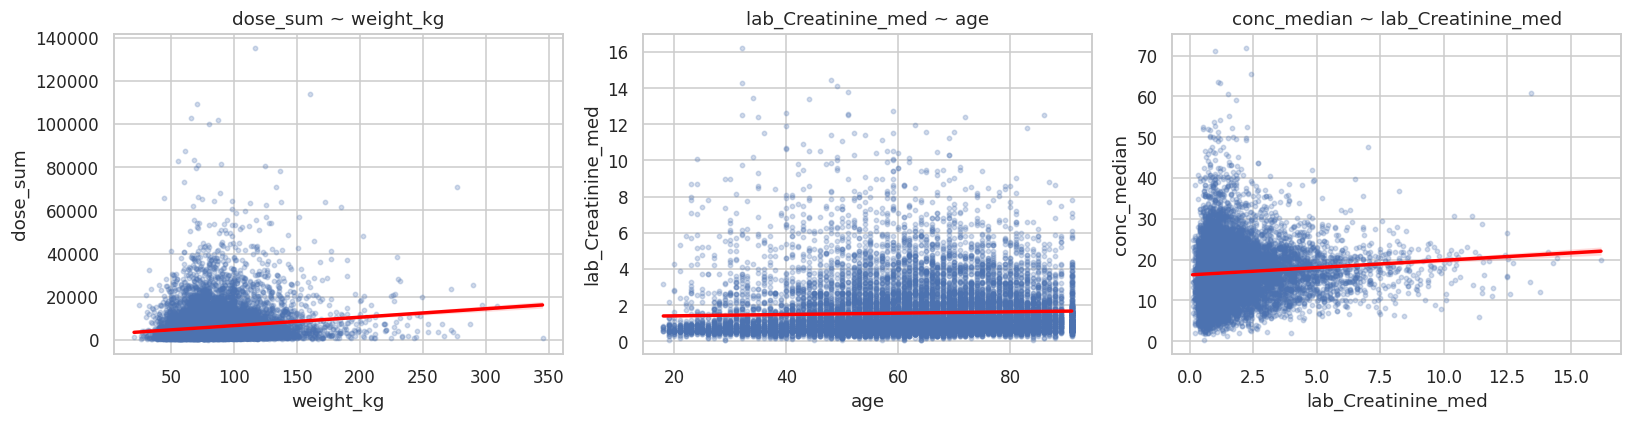

In [27]:
# Scatter + regression grid for a few key pairs
pairs = [("weight_kg", "dose_sum"), ("age", "lab_Creatinine_med"),
         ("lab_Creatinine_med", "conc_median")]
pairs = [(x, y) for x, y in pairs if {x, y}.issubset(stay.columns)]
fig, ax = plt.subplots(1, len(pairs), figsize=(5*len(pairs), 4))
ax = np.atleast_1d(ax)
for k, (x, y) in enumerate(pairs):
    d = stay[[x, y]].dropna()
    sns.regplot(x=x, y=y, data=d, ax=ax[k],
                scatter_kws={"s": 8, "alpha": .25}, line_kws={"color": "red"})
    ax[k].set_title(f"{y} ~ {x}")
plt.tight_layout(); plt.show()

### Categorical vs Numerical — assumption-driven test selection
#
For each (categorical, numerical) pair we check sample size, normality
(Shapiro per group), and variance homogeneity (Levene). The decision logic:
#
```
IF all groups ~normal AND variances homogeneous:
    2 groups -> independent t-test ; >2 groups -> one-way ANOVA
ELIF all groups ~normal AND variances UNequal:
    2 groups -> Welch t-test
ELSE:
    2 groups -> Mann-Whitney U ; >2 groups -> Kruskal-Wallis
```
Always reporting effect size + CI + interpretation.

In [28]:
def cat_num_test(df, cat, num, alpha=0.05):
    d = df[[cat, num]].dropna()
    groups = [g[num].values for _, g in d.groupby(cat)]
    groups = [g for g in groups if len(g) >= 3]
    if len(groups) < 2:
        return None
    sizes = [len(g) for g in groups]
    # normality per group (subsample for shapiro)
    norm_ok = all(ss.shapiro(g if len(g) <= 5000 else RNG.choice(g, 5000))[1] > alpha
                  for g in groups)
    var_ok = ss.levene(*groups)[1] > alpha
    res = {"cat": cat, "num": num, "n_groups": len(groups), "sizes": sizes,
           "normal": norm_ok, "equal_var": var_ok}
    if len(groups) == 2:
        a, b = groups
        if norm_ok and var_ok:
            res["test"] = "independent t-test"
            stat, p = ss.ttest_ind(a, b, equal_var=True)
            res["effect"] = f"Cohen d={cohens_d(a,b):.3f}"
        elif norm_ok and not var_ok:
            res["test"] = "Welch t-test"
            stat, p = ss.ttest_ind(a, b, equal_var=False)
            res["effect"] = f"Cohen d={cohens_d(a,b):.3f}"
        else:
            res["test"] = "Mann-Whitney U"
            stat, p = ss.mannwhitneyu(a, b, alternative="two-sided")
            res["effect"] = f"Cliff delta={cliffs_delta(a,b):.3f}"
        diff = np.mean(a) - np.mean(b)
        res["mean_diff"] = diff
        # bootstrap CI of the mean difference
        boot = [RNG.choice(a, len(a)).mean() - RNG.choice(b, len(b)).mean()
                for _ in range(1500)]
        res["diff_CI95"] = tuple(np.percentile(boot, [2.5, 97.5]).round(3))
    else:
        if norm_ok and var_ok:
            res["test"] = "one-way ANOVA"
            stat, p = ss.f_oneway(*groups)
        else:
            res["test"] = "Kruskal-Wallis"
            stat, p = ss.kruskal(*groups)
        res["effect"] = f"eta^2={eta_squared(groups):.3f}"
    res["stat"] = round(stat, 4); res["p"] = p
    res["result"] = interpret_p(p)
    return res

cn_pairs = [("sex", "conc_median"), ("has_crrt", "conc_median"),
            ("has_invasive_vent", "los_icu_hrs"),
            ("has_vasopressor", "lab_Creatinine_med"),
            ("has_hd", "dose_sum")]
rows = [cat_num_test(stay, c, n) for c, n in cn_pairs]
cn_df = pd.DataFrame([r for r in rows if r])
display(cn_df)

,cat,num,n_groups,sizes,normal,equal_var,test,effect,mean_diff,diff_CI95,stat,p,result
0,sex,conc_median,2,"[6656, 9739]",False,False,Mann-Whitney U,Cliff delta=0.042,0.4849,"(0.284, 0.685)","33,761,906.5000",0.0000,significant
1,has_crrt,conc_median,2,"[14806, 1589]",False,False,Mann-Whitney U,Cliff delta=-0.046,-0.3973,"(-0.709, -0.091)","11,217,758.0000",0.0023,significant
2,has_invasive_vent,los_icu_hrs,2,"[6359, 10101]",False,False,Mann-Whitney U,Cliff delta=-0.671,-179.8805,"(-184.639, -174.802)","10,575,338.0000",0.0000,significant
3,has_vasopressor,lab_Creatinine_med,2,"[10226, 6232]",False,False,Mann-Whitney U,Cliff delta=-0.237,-0.3272,"(-0.371, -0.283)","24,324,557.0000",0.0000,significant
4,has_hd,dose_sum,2,"[15241, 1219]",False,False,Mann-Whitney U,Cliff delta=0.212,"1,270.1196","(880.526, 1649.928)","11,260,792.5000",0.0000,significant


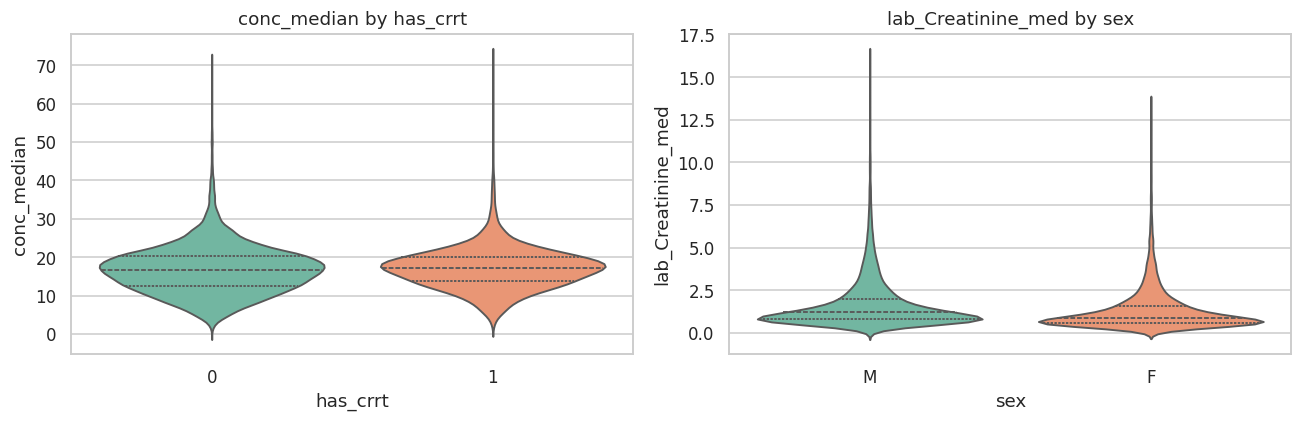

In [29]:
# Visualise a couple: box + violin
viz = [("has_crrt", "conc_median"), ("sex", "lab_Creatinine_med")]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (c, n) in enumerate(viz):
    d = stay[[c, n]].dropna()
    sns.violinplot(x=c, y=n, data=d, ax=ax[k], inner="quartile", palette="Set2")
    ax[k].set_title(f"{n} by {c}")
plt.tight_layout(); plt.show()

### Categorical vs Categorical
Contingency tables, expected counts, Chi-square **or** Fisher exact
(decision on expected-cell counts), Cramér's V, odds ratios, mosaic / stacked
bar visualisation.

,a,b,shape,min_expected,test,p,chi2,dof,odds_ratio,cramers_v,result
0,sex,has_crrt,"(2, 2)",646.2600,Chi-square,0.1100,2.5550,1,1.0920,0.0100,not significant
1,has_invasive_vent,has_vasopressor,"(2, 2)","2,407.6100",Chi-square,0.0000,"2,477.3370",1,6.7930,0.3880,significant
2,has_hd,has_crrt,"(2, 2)",117.8300,Chi-square,0.0000,"1,988.3230",1,11.7630,0.3480,significant
3,sex,has_invasive_vent,"(2, 2)","2,583.0100",Chi-square,0.0004,12.5060,1,1.1220,0.0270,significant


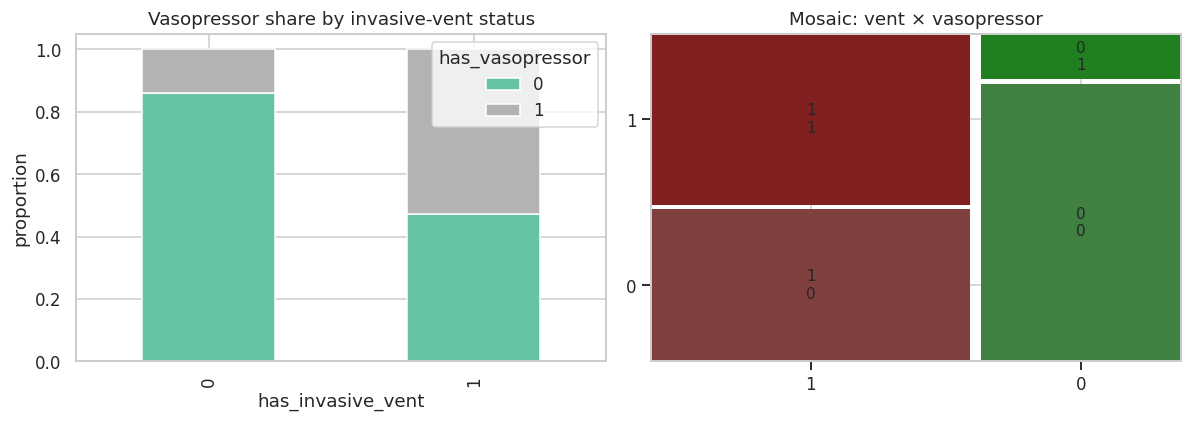

In [30]:
def cat_cat_test(df, a, b):
    d = df[[a, b]].dropna()
    ct = pd.crosstab(d[a], d[b])
    chi2, p_chi, dof, expected = ss.chi2_contingency(ct)
    min_exp = expected.min()
    use_fisher = (ct.shape == (2, 2)) and (min_exp < 5)
    res = {"a": a, "b": b, "shape": ct.shape,
           "min_expected": round(min_exp, 2)}
    if use_fisher:
        odds, p = ss.fisher_exact(ct)
        res["test"] = "Fisher exact"; res["p"] = p
        res["odds_ratio"] = round(odds, 3)
    else:
        res["test"] = "Chi-square"; res["p"] = p_chi
        res["chi2"] = round(chi2, 3); res["dof"] = dof
        if ct.shape == (2, 2):
            # OR from 2x2
            (a11, a12), (a21, a22) = ct.values
            res["odds_ratio"] = round((a11*a22)/((a12*a21) or np.nan), 3)
    res["cramers_v"] = round(cramers_v(ct), 3)
    res["result"] = interpret_p(res["p"])
    return res, ct

cc_pairs = [("sex", "has_crrt"), ("has_invasive_vent", "has_vasopressor"),
            ("has_hd", "has_crrt"), ("sex", "has_invasive_vent")]
cc_rows = []
for a, b in cc_pairs:
    r, ct = cat_cat_test(cov, a, b)
    cc_rows.append(r)
display(pd.DataFrame(cc_rows))

# Stacked bar + mosaic-style for one pair
ct = pd.crosstab(cov.has_invasive_vent, cov.has_vasopressor, normalize="index")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ct.plot(kind="bar", stacked=True, ax=ax[0], colormap="Set2")
ax[0].set_title("Vasopressor share by invasive-vent status")
ax[0].set_ylabel("proportion")
# mosaic
if statsmodels:
    from statsmodels.graphics.mosaicplot import mosaic
    mosaic(cov, ["has_invasive_vent", "has_vasopressor"], ax=ax[1],
           gap=0.02, title="Mosaic: vent × vasopressor")
plt.tight_layout(); plt.show()

## 8. Multivariate Analysis
Pairplot, correlation clustering, multicollinearity (VIF + condition number),
and PCA (explained variance, loadings, scree).

Multivariate complete-case n = 6701


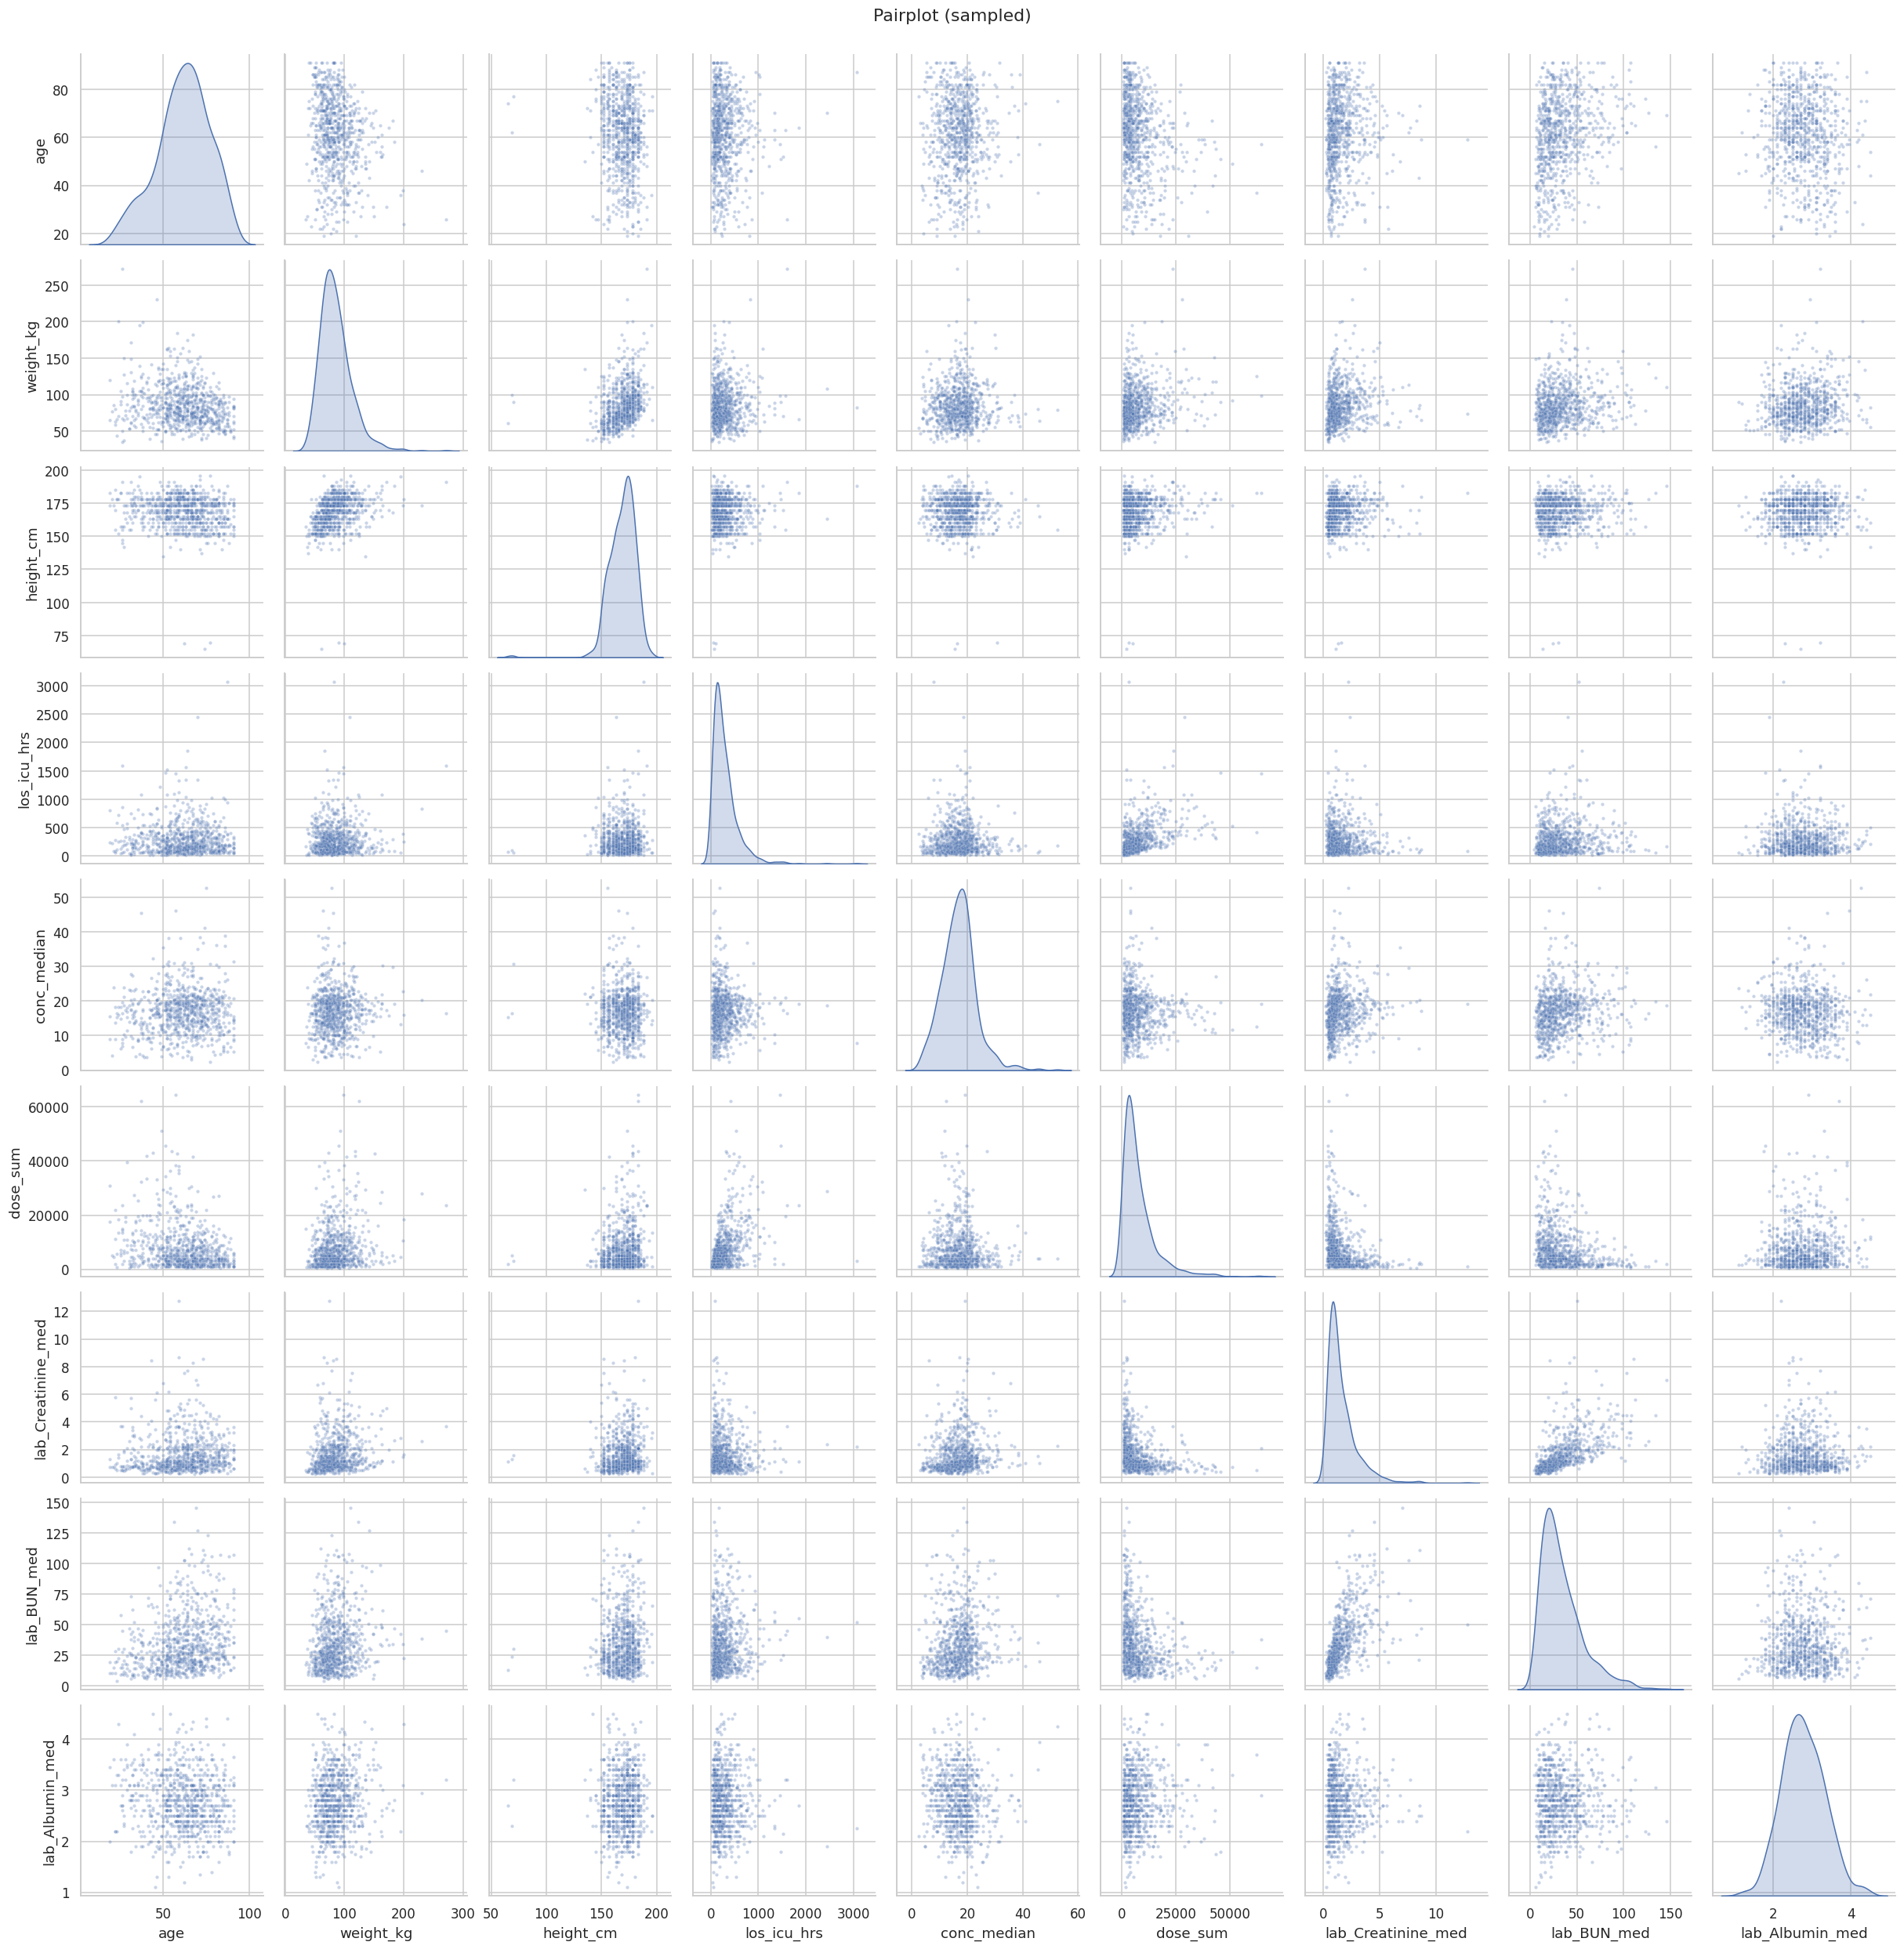

In [31]:
MV = ["age", "weight_kg", "height_cm", "los_icu_hrs", "conc_median",
      "dose_sum", "lab_Creatinine_med", "lab_BUN_med", "lab_Albumin_med"]
MV = [c for c in MV if c in stay.columns]
Xmv = stay[MV].dropna()
print("Multivariate complete-case n =", len(Xmv))

# Pairplot
sns.pairplot(Xmv.sample(min(800, len(Xmv)), random_state=1),
             diag_kind="kde", plot_kws={"s": 8, "alpha": .3})
plt.suptitle("Pairplot (sampled)", y=1.01); plt.show()

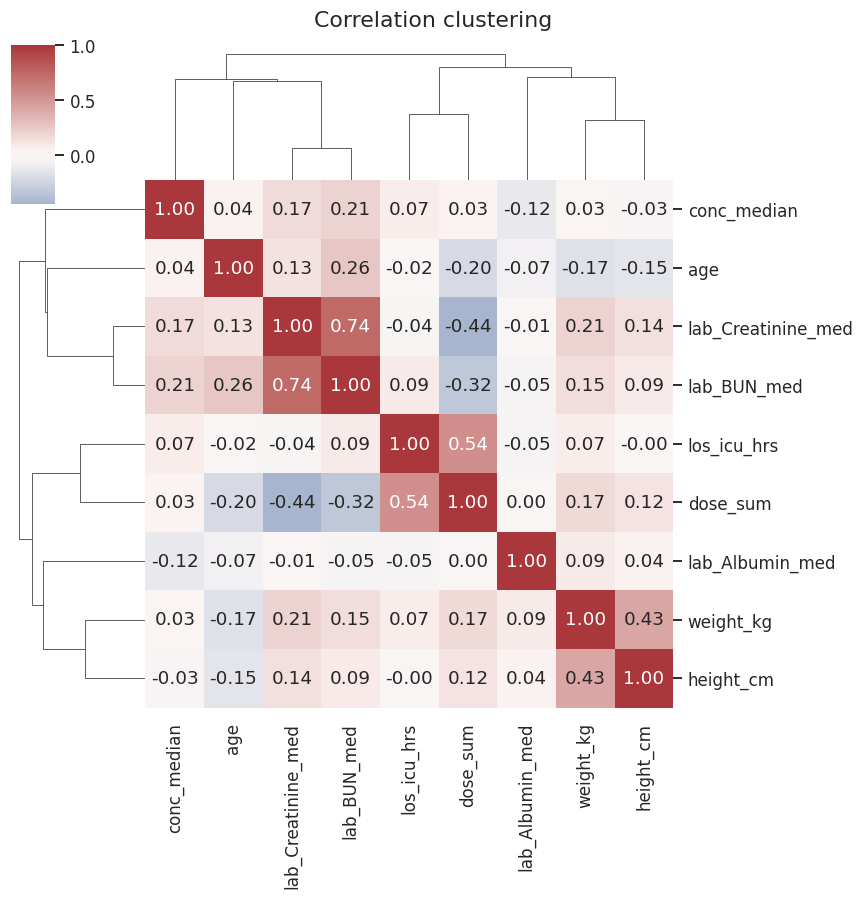

In [32]:
# Correlation clustering (clustermap on Spearman)
corr = Xmv.corr(method="spearman")
sns.clustermap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
               figsize=(8, 8))
plt.suptitle("Correlation clustering", y=1.02); plt.show()

In [33]:
# Multicollinearity: VIF + condition number
Xs = StandardScaler().fit_transform(Xmv)
if statsmodels:
    vif = pd.DataFrame({
        "feature": MV,
        "VIF": [variance_inflation_factor(Xs, i) for i in range(Xs.shape[1])]
    }).sort_values("VIF", ascending=False)
    display(vif)
cond = np.linalg.cond(Xs)
print(f"Condition number (standardised design): {cond:,.1f}  "
      f"({'concerning >30' if cond > 30 else 'acceptable'})")

,feature,VIF
7,lab_BUN_med,1.7918
6,lab_Creatinine_med,1.7215
5,dose_sum,1.5663
3,los_icu_hrs,1.3527
1,weight_kg,1.2131
2,height_cm,1.1751
0,age,1.1554
4,conc_median,1.0426
8,lab_Albumin_med,1.0238


Condition number (standardised design): 2.4  (acceptable)


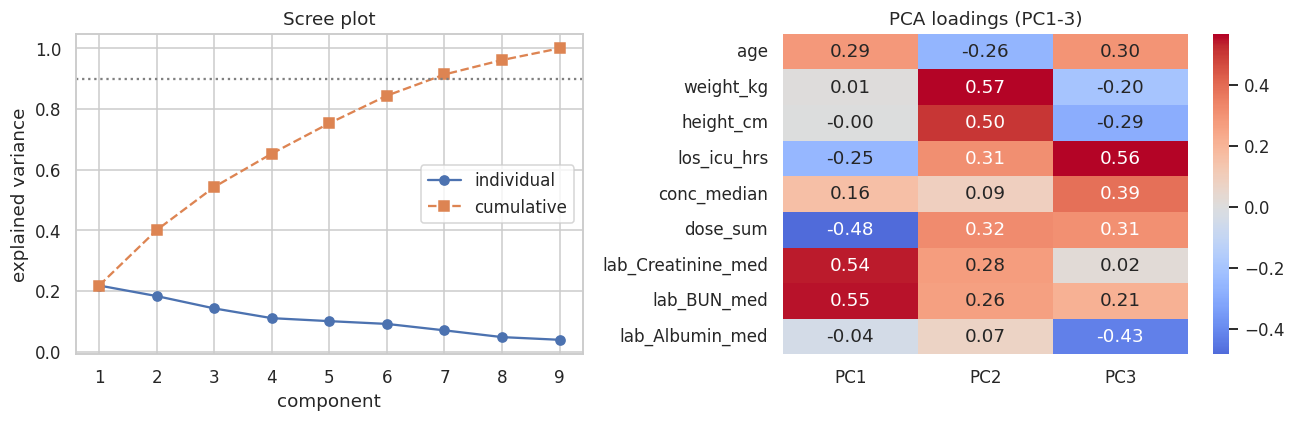

Explained variance ratio: [0.218 0.183 0.142 0.11  0.1   0.091 0.07  0.048 0.039]
Cumulative: [0.218 0.401 0.543 0.653 0.753 0.844 0.914 0.961 1.   ]


In [34]:
# PCA
pca = PCA().fit(Xs)
evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(evr)+1), evr, "o-", label="individual")
ax[0].plot(range(1, len(evr)+1), np.cumsum(evr), "s--", label="cumulative")
ax[0].axhline(0.9, color="grey", ls=":"); ax[0].set_xlabel("component")
ax[0].set_ylabel("explained variance"); ax[0].set_title("Scree plot"); ax[0].legend()
loadings = pd.DataFrame(pca.components_[:3].T, index=MV,
                        columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("PCA loadings (PC1-3)")
plt.tight_layout(); plt.show()
print("Explained variance ratio:", np.round(evr, 3))
print("Cumulative:", np.round(np.cumsum(evr), 3))

## 10. Feature Importance Screening
We screen per-stay features against two targets:
**numerical** target = `conc_median` (mutual information + correlation ranking);
**categorical** target = `has_crrt` (renal-replacement; MI + ANOVA F + Chi-square).

In [35]:
# --- Numerical target: conc_median ---
feat_cols = ["age", "weight_kg", "height_cm", "los_icu_hrs", "dose_sum",
             "lab_Creatinine_med", "lab_BUN_med", "lab_Albumin_med"]
feat_cols = [c for c in feat_cols if c in stay.columns]
dnum = stay[feat_cols + ["conc_median"]].dropna()
Xn, yn = dnum[feat_cols], dnum["conc_median"]
mi = mutual_info_regression(Xn, yn, random_state=0)
pear = [abs(ss.pearsonr(Xn[c], yn)[0]) for c in feat_cols]
spear = [abs(ss.spearmanr(Xn[c], yn)[0]) for c in feat_cols]
rank_num = pd.DataFrame({"feature": feat_cols, "mutual_info": mi,
                         "|pearson|": pear, "|spearman|": spear})
rank_num = rank_num.sort_values("mutual_info", ascending=False)
print("Feature importance — numerical target (conc_median):")
display(rank_num)

Feature importance — numerical target (conc_median):


,feature,mutual_info,|pearson|,|spearman|
6,lab_BUN_med,0.0352,0.1614,0.2075
0,age,0.0327,0.0448,0.0437
3,los_icu_hrs,0.0280,0.0241,0.0727
5,lab_Creatinine_med,0.0276,0.0977,0.1656
4,dose_sum,0.0119,0.0048,0.0349
7,lab_Albumin_med,0.0048,0.1048,0.1162
2,height_cm,0.0000,0.0355,0.0347
1,weight_kg,0.0000,0.0344,0.0258


In [36]:
# --- Categorical target: has_crrt ---
dcat = stay[feat_cols + ["has_crrt"]].dropna()
Xc, yc = dcat[feat_cols], dcat["has_crrt"].astype(int)
mi_c = mutual_info_classif(Xc, yc, random_state=0)
f_vals, f_p = f_classif(Xc, yc)
# chi-square needs non-negative; use binned features
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.feature_selection import chi2
Xb = KBinsDiscretizer(n_bins=5, encode="ordinal",
                      strategy="quantile").fit_transform(Xc)
chi_vals, chi_p = chi2(Xb, yc)
rank_cat = pd.DataFrame({"feature": feat_cols, "mutual_info": mi_c,
                         "anova_F": f_vals, "anova_p": f_p,
                         "chi2": chi_vals, "chi2_p": chi_p})
rank_cat = rank_cat.sort_values("mutual_info", ascending=False)
print("Feature importance — categorical target (has_crrt):")
display(rank_cat)

Feature importance — categorical target (has_crrt):


,feature,mutual_info,anova_F,anova_p,chi2,chi2_p
5,lab_Creatinine_med,0.0807,402.4680,0.0000,787.2700,0.0000
3,los_icu_hrs,0.0277,435.5818,0.0000,365.5582,0.0000
6,lab_BUN_med,0.0067,36.0369,0.0000,99.3517,0.0000
1,weight_kg,0.0057,92.7050,0.0000,107.3771,0.0000
7,lab_Albumin_med,0.0028,10.4200,0.0013,17.1051,0.0000
0,age,0.0020,12.7615,0.0004,14.5240,0.0001
2,height_cm,0.0020,5.8943,0.0152,3.1214,0.0773
4,dose_sum,0.0000,2.6420,0.1041,0.6513,0.4197


## 11. Statistical Summary Report

In [37]:
report = []
# cat-num tests
for r in [x for x in rows if x]:
    report.append({
        "comparison": f"{r['num']} by {r['cat']}",
        "test": r["test"],
        "assumptions": f"normal={r['normal']}, equal_var={r['equal_var']}",
        "statistic": r["stat"], "p_value": r["p"],
        "effect_size": r["effect"],
        "CI95": r.get("diff_CI95", "—"),
        "interpretation": r["result"]})
# cat-cat tests
for r in cc_rows:
    report.append({
        "comparison": f"{r['a']} × {r['b']}",
        "test": r["test"],
        "assumptions": f"min_expected={r['min_expected']}",
        "statistic": r.get("chi2", r.get("odds_ratio", "—")),
        "p_value": r["p"],
        "effect_size": f"Cramér V={r['cramers_v']}",
        "CI95": "—", "interpretation": r["result"]})
report_df = pd.DataFrame(report)
display(report_df)
# also expose descriptive + normality tables already computed
print("\nNormality summary (from §6):"); display(nrm[["n", "shapiro_p",
      "dagostino_p", "skew", "kurtosis", "transform_reco"]])

,comparison,test,assumptions,statistic,p_value,effect_size,CI95,interpretation
0,conc_median by sex,Mann-Whitney U,"normal=False, equal_var=False","33,761,906.5000",0.0000,Cliff delta=0.042,"(0.284, 0.685)",significant
1,conc_median by has_crrt,Mann-Whitney U,"normal=False, equal_var=False","11,217,758.0000",0.0023,Cliff delta=-0.046,"(-0.709, -0.091)",significant
2,los_icu_hrs by has_invasive_vent,Mann-Whitney U,"normal=False, equal_var=False","10,575,338.0000",0.0000,Cliff delta=-0.671,"(-184.639, -174.802)",significant
3,lab_Creatinine_med by has_vasopressor,Mann-Whitney U,"normal=False, equal_var=False","24,324,557.0000",0.0000,Cliff delta=-0.237,"(-0.371, -0.283)",significant
4,dose_sum by has_hd,Mann-Whitney U,"normal=False, equal_var=False","11,260,792.5000",0.0000,Cliff delta=0.212,"(880.526, 1649.928)",significant
5,sex × has_crrt,Chi-square,min_expected=646.26,2.5550,0.1100,Cramér V=0.01,—,not significant
6,has_invasive_vent × has_vasopressor,Chi-square,min_expected=2407.61,"2,477.3370",0.0000,Cramér V=0.388,—,significant
7,has_hd × has_crrt,Chi-square,min_expected=117.83,"1,988.3230",0.0000,Cramér V=0.348,—,significant
8,sex × has_invasive_vent,Chi-square,min_expected=2583.01,12.5060,0.0004,Cramér V=0.027,—,significant



Normality summary (from §6):


,n,shapiro_p,dagostino_p,skew,kurtosis,transform_reco
age,16460,0.0000,0.0000,-0.4450,-0.2263,none
los_icu_hrs,16460,0.0000,0.0000,3.1761,19.1923,log / Box-Cox (all-positive) — strong right skew
weight_kg,14802,0.0000,0.0000,1.6985,6.7049,log / Box-Cox (all-positive) — strong right skew
height_cm,10104,0.0000,0.0000,-1.8094,13.1777,Yeo-Johnson (handles negatives)
dose_mg,121672,0.0000,0.0000,0.8042,1.9235,sqrt / Yeo-Johnson
concentration,83094,0.0000,0.0000,2.8887,50.4716,log / Box-Cox (all-positive) — strong right skew
lab_Creatinine,248383,0.0000,0.0000,3.1750,40.9721,log / Box-Cox (all-positive) — strong right skew
lab_BUN,248014,0.0000,0.0000,1.7140,4.0921,log / Box-Cox (all-positive) — strong right skew
lab_Albumin,36245,0.0000,0.0000,0.4311,0.6213,none
lab_ALT,75319,0.0000,0.0000,15.7617,767.1130,log / Box-Cox (all-positive) — strong right skew


## 12. Time-Series and Event Analysis
`intime`/`outtime` are true timestamps; `time_hours` is relative-to-admission.
We validate timestamps, profile temporal coverage, event frequency,
inter-event times, trend, and time-based missingness.

### Timestamp validation

In [38]:
ts_cols = ["intime", "outtime"]
for c in ts_cols:
    s = cov[c]
    print(f"\n[{c}]")
    print("  parsed as datetime :", pd.api.types.is_datetime64_any_dtype(s))
    print("  NaT / unparsed     :", s.isna().sum())
    print("  tz-aware           :", s.dt.tz is not None)
    print("  future dates (> now):", (s > pd.Timestamp.now()).sum())
    print("  duplicate values   :", s.duplicated().sum())
    print("  range              :", s.min(), "→", s.max())
# logical validity: outtime after intime, and LOS consistency
bad_order = (cov.outtime < cov.intime).sum()
recomputed = (cov.outtime - cov.intime).dt.total_seconds()/3600
los_disc = (np.abs(recomputed - cov.los_icu_hrs) > 1).sum()
print(f"\nouttime < intime          : {bad_order}")
print(f"LOS disagreement (>1 hr)  : {los_disc}  "
      f"(median abs diff = {np.nanmedian(np.abs(recomputed-cov.los_icu_hrs)):.3f} hr)")
print("NOTE: MIMIC-IV dates are de-identified into the future (2110-2210); "
      "'future dates' are expected and not errors.")


[intime]
  parsed as datetime : True
  NaT / unparsed     : 0
  tz-aware           : False
  future dates (> now): 16460
  duplicate values   : 1
  range              : 2110-01-16 04:28:00 → 2210-10-19 21:08:00

[outtime]
  parsed as datetime : True
  NaT / unparsed     : 0
  tz-aware           : False
  future dates (> now): 16460
  duplicate values   : 0
  range              : 2110-01-17 17:51:08 → 2210-11-02 17:45:11

outtime < intime          : 0
LOS disagreement (>1 hr)  : 0  (median abs diff = 0.000 hr)
NOTE: MIMIC-IV dates are de-identified into the future (2110-2210); 'future dates' are expected and not errors.


### Temporal coverage

Start (earliest admission): 2110-01-16 04:28:00
End   (latest discharge)  : 2210-11-02 17:45:11
Observation period        : 36814 days 13:17:11
Unique days   : 12917
Unique weeks  : 4585
Unique months : 1173


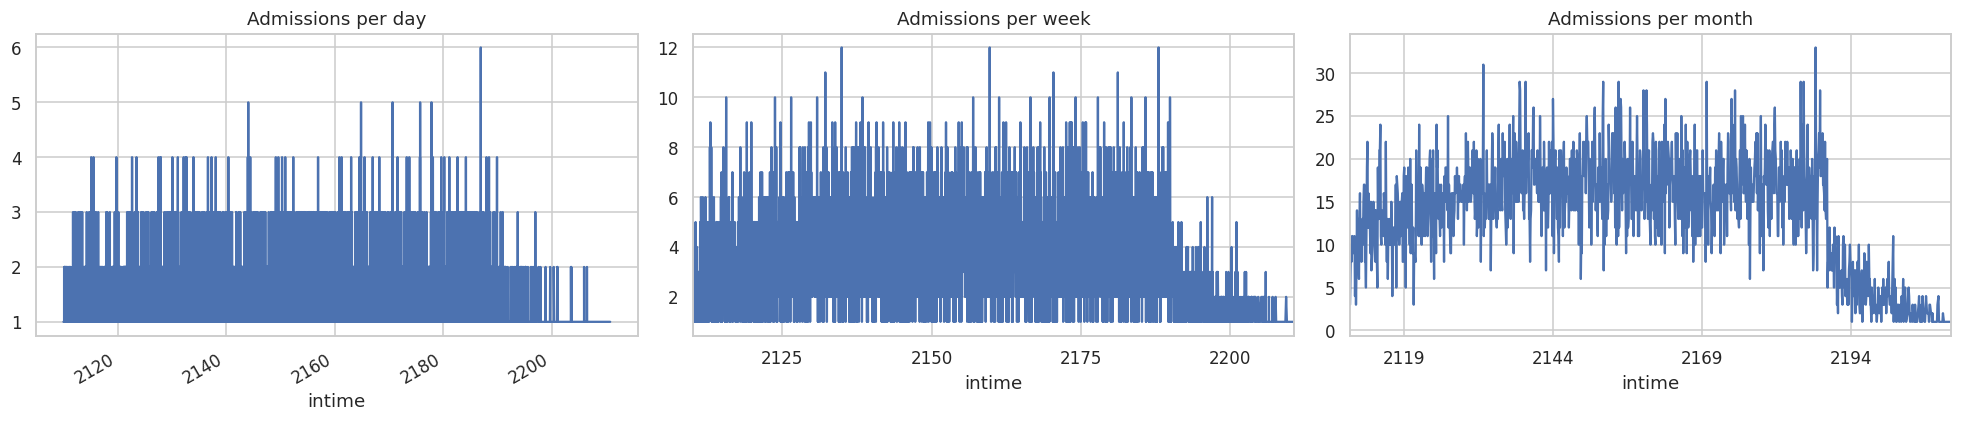

Largest admission-day gaps (>5× median): 289 found; max gap = 346 days 00:00:00


In [39]:
intime = cov.intime
print("Start (earliest admission):", intime.min())
print("End   (latest discharge)  :", cov.outtime.max())
period = cov.outtime.max() - intime.min()
print("Observation period        :", period)
print("Unique days   :", intime.dt.normalize().nunique())
print("Unique weeks  :", intime.dt.to_period("W").nunique())
print("Unique months :", intime.dt.to_period("M").nunique())

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
intime.dt.normalize().value_counts().sort_index().plot(ax=ax[0])
ax[0].set_title("Admissions per day")
intime.dt.to_period("W").value_counts().sort_index().plot(ax=ax[1])
ax[1].set_title("Admissions per week")
intime.dt.to_period("M").value_counts().sort_index().plot(ax=ax[2])
ax[2].set_title("Admissions per month")
plt.tight_layout(); plt.show()

# temporal gaps in admission days
days = pd.Series(sorted(intime.dt.normalize().unique()))
gaps = days.diff().dropna()
big = gaps[gaps > gaps.median()*5]
print(f"Largest admission-day gaps (>5× median): {len(big)} found; "
      f"max gap = {gaps.max()}")

### Event frequency analysis (using relative `time_hours`)
We bucket dose & concentration events by elapsed ICU time to expose the
treatment/sampling rhythm and peak/low-activity windows.

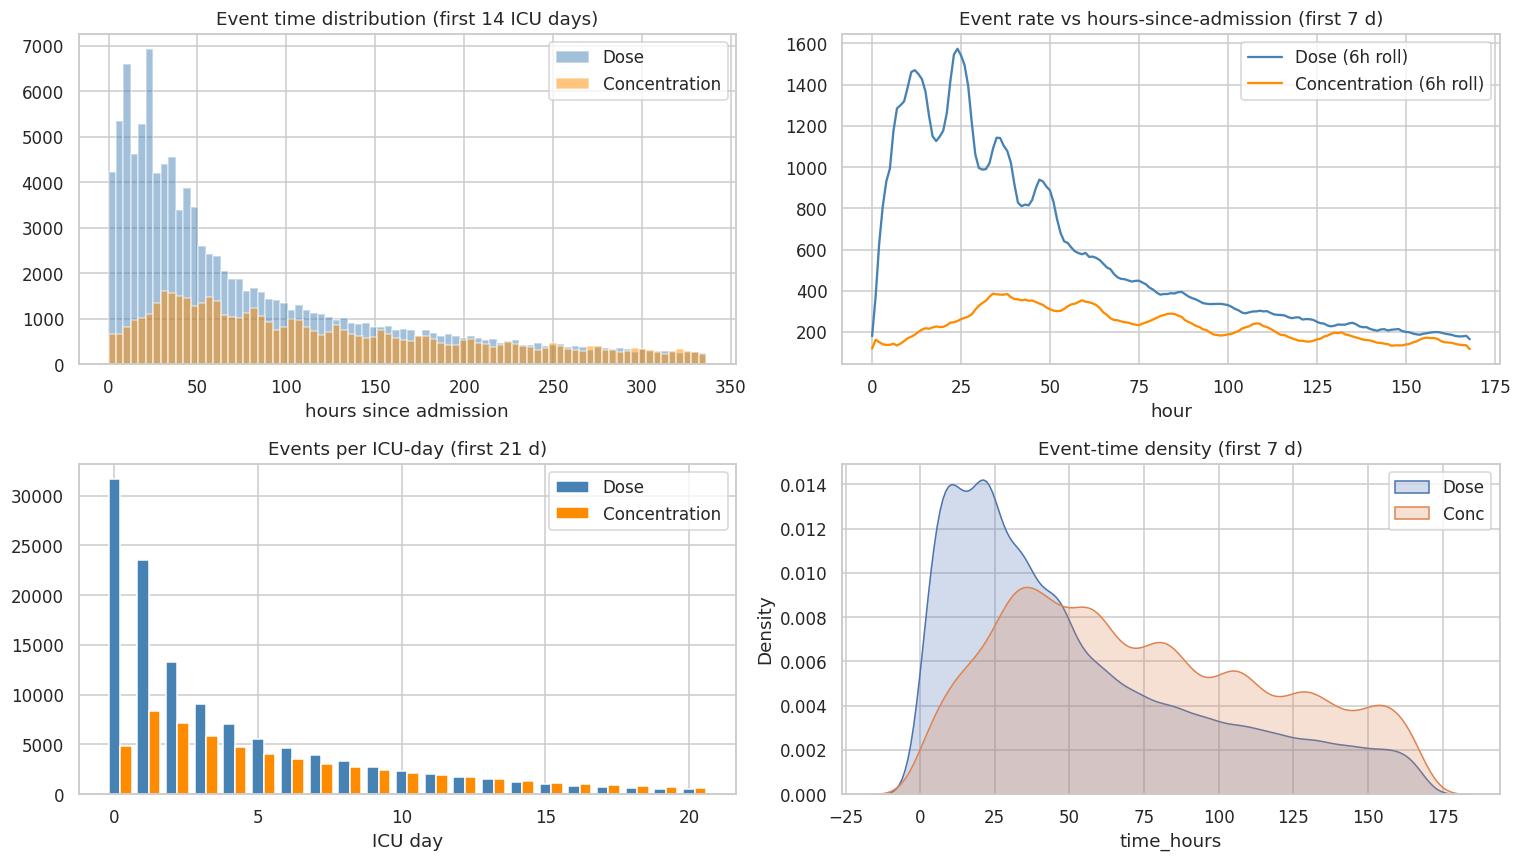

Median dose events / stay        : 3.0
Median concentration events / stay: 2.0


In [40]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for d, nm, c in [(dose, "Dose", "steelblue"), (conc, "Concentration", "darkorange")]:
    t = d.loc[d.time_hours.between(0, 24*14), "time_hours"]  # first 14 ICU days
    ax[0, 0].hist(t, bins=80, alpha=.5, label=nm, color=c)
ax[0, 0].set_title("Event time distribution (first 14 ICU days)")
ax[0, 0].set_xlabel("hours since admission"); ax[0, 0].legend()

# events per hour-of-stay (rate curve, rolling mean)
for d, nm, c in [(dose, "Dose", "steelblue"), (conc, "Concentration", "darkorange")]:
    hr = d.loc[d.time_hours.between(0, 24*7), "time_hours"].round()
    rate = hr.value_counts().sort_index()
    ax[0, 1].plot(rate.index, rate.rolling(6, min_periods=1).mean(),
                  label=f"{nm} (6h roll)", color=c)
ax[0, 1].set_title("Event rate vs hours-since-admission (first 7 d)")
ax[0, 1].set_xlabel("hour"); ax[0, 1].legend()

# events per ICU-day
for d, nm, c in [(dose, "Dose", "steelblue"), (conc, "Concentration", "darkorange")]:
    day = (d.loc[d.time_hours >= 0, "time_hours"]//24).astype(int)
    dd = day[day < 21].value_counts().sort_index()
    ax[1, 0].bar(dd.index + (0 if nm == "Dose" else 0.4), dd.values,
                 width=0.4, label=nm, color=c)
ax[1, 0].set_title("Events per ICU-day (first 21 d)")
ax[1, 0].set_xlabel("ICU day"); ax[1, 0].legend()

# density
sns.kdeplot(dose.loc[dose.time_hours.between(0, 24*7), "time_hours"],
            ax=ax[1, 1], label="Dose", fill=True)
sns.kdeplot(conc.loc[conc.time_hours.between(0, 24*7), "time_hours"],
            ax=ax[1, 1], label="Conc", fill=True)
ax[1, 1].set_title("Event-time density (first 7 d)"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

# numeric rates
hours_span = dose.loc[dose.time_hours.between(0, 24*30)]
print("Median dose events / stay        :",
      dose.groupby("stay_id").size().median())
print("Median concentration events / stay:",
      conc.groupby("stay_id").size().median())

### Inter-event time analysis
Per stay, the gaps between successive dose administrations (the de-facto dosing
interval) and between concentration draws.

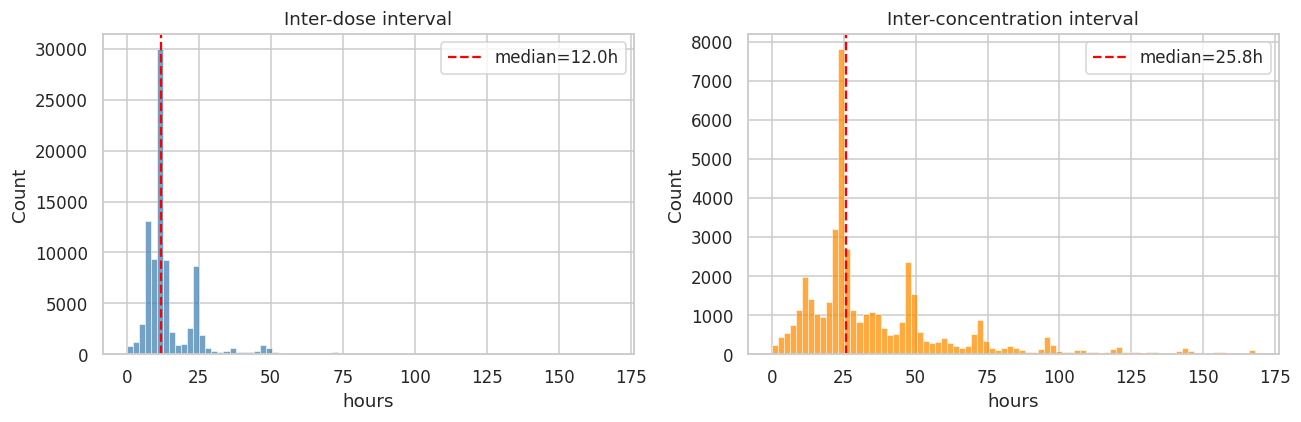

Inter-dose: median=12.00h, common modes near 8/12/24h reflect standard dosing schedules.


In [41]:
def inter_event(df, val="time_hours"):
    df = df[df.time_hours >= 0].sort_values(["stay_id", "time_hours"])
    gaps = df.groupby("stay_id")[val].diff().dropna()
    return gaps[(gaps > 0) & (gaps < 24*7)]  # plausible windows

dose_gap = inter_event(dose)
conc_gap = inter_event(conc)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(dose_gap, bins=80, ax=ax[0], color="steelblue")
ax[0].axvline(dose_gap.median(), color="red", ls="--",
              label=f"median={dose_gap.median():.1f}h")
ax[0].set_title("Inter-dose interval"); ax[0].set_xlabel("hours"); ax[0].legend()
sns.histplot(conc_gap, bins=80, ax=ax[1], color="darkorange")
ax[1].axvline(conc_gap.median(), color="red", ls="--",
              label=f"median={conc_gap.median():.1f}h")
ax[1].set_title("Inter-concentration interval"); ax[1].set_xlabel("hours")
ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Inter-dose: median={dose_gap.median():.2f}h, "
      f"common modes near 8/12/24h reflect standard dosing schedules.")

### Trend analysis — concentration over ICU time
Linear trend, moving average, Mann–Kendall trend test, and (where a regular
series can be formed) seasonal decomposition.

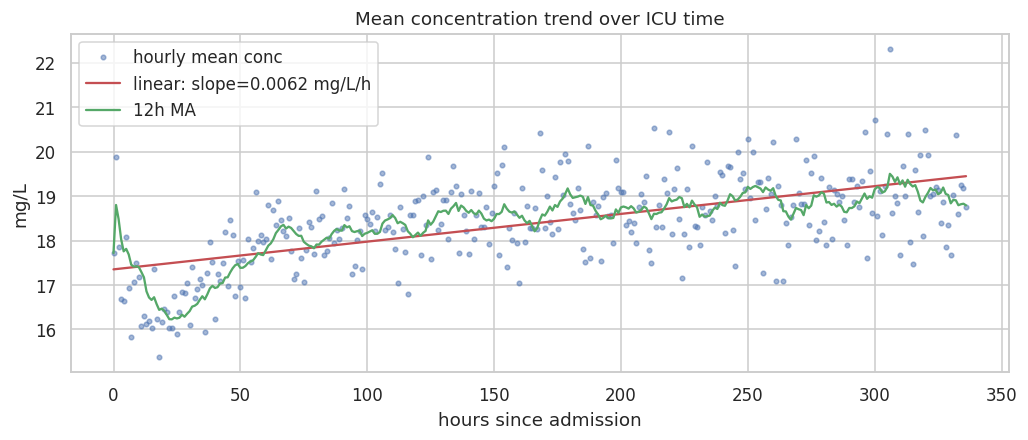

Linear trend slope=0.0062 mg/L/h, 95% CI[0.0053,0.0071], r=0.592, p=2.75e-33 (significant)
Mann-Kendall: z=11.280, p=0.000e+00, trend=increasing (significant)


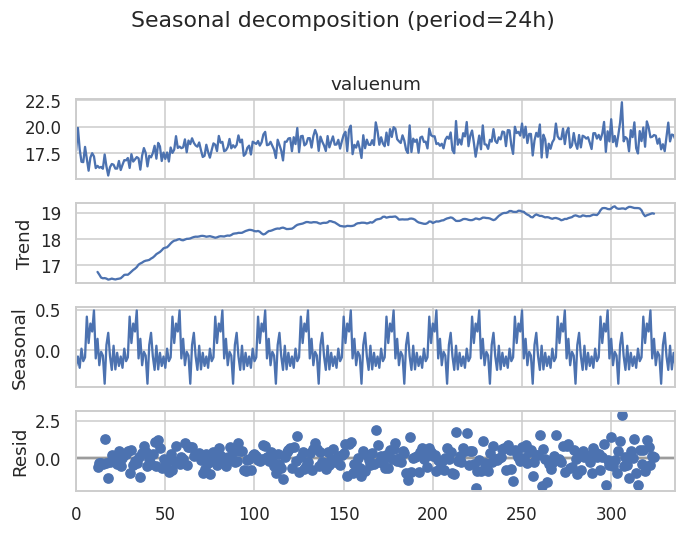

In [42]:
# Population-level mean concentration vs hour-of-stay
binned = (conc[conc.time_hours.between(0, 24*14)]
          .assign(hr=lambda d: d.time_hours.round())
          .groupby("hr")["valuenum"].mean())
x = binned.index.values.astype(float); y = binned.values
slope, intercept, r, p, se = ss.linregress(x, y)
ci_slope = (slope-1.96*se, slope+1.96*se)
plt.figure(figsize=(11, 4))
plt.plot(x, y, ".", alpha=.5, label="hourly mean conc")
plt.plot(x, intercept+slope*x, "r-",
         label=f"linear: slope={slope:.4f} mg/L/h")
plt.plot(x, binned.rolling(12, min_periods=1).mean(), "g-", label="12h MA")
plt.title("Mean concentration trend over ICU time"); plt.legend()
plt.xlabel("hours since admission"); plt.ylabel("mg/L"); plt.show()
print(f"Linear trend slope={slope:.4f} mg/L/h, 95% CI[{ci_slope[0]:.4f},"
      f"{ci_slope[1]:.4f}], r={r:.3f}, p={p:.2e} ({interpret_p(p)})")

# Mann-Kendall trend test (no external dep)
def mann_kendall(x):
    x = np.asarray(x, float); n = len(x)
    s = sum(np.sign(x[j]-x[i]) for i in range(n-1) for j in range(i+1, n))
    var = n*(n-1)*(2*n+5)/18
    z = (s-np.sign(s))/np.sqrt(var) if s != 0 else 0
    p = 2*(1-ss.norm.cdf(abs(z)))
    trend = "increasing" if z > 0 else "decreasing" if z < 0 else "none"
    return z, p, trend
z, p_mk, trend = mann_kendall(y)
print(f"Mann-Kendall: z={z:.3f}, p={p_mk:.3e}, trend={trend} ({interpret_p(p_mk)})")

# Seasonal decomposition on the regular hourly mean series
if statsmodels and len(binned) >= 48:
    dec = seasonal_decompose(binned.interpolate(), period=24, model="additive")
    dec.plot(); plt.suptitle("Seasonal decomposition (period=24h)", y=1.01)
    plt.tight_layout(); plt.show()

### Time-based missingness
Is lab missingness random or time-dependent? We track, across ICU days, how
many active stays have ≥1 of each lab vs how many do not — exposing whether
certain analytes (e.g. albumin) are systematically sampled less over time
(informative / time-dependent missingness).

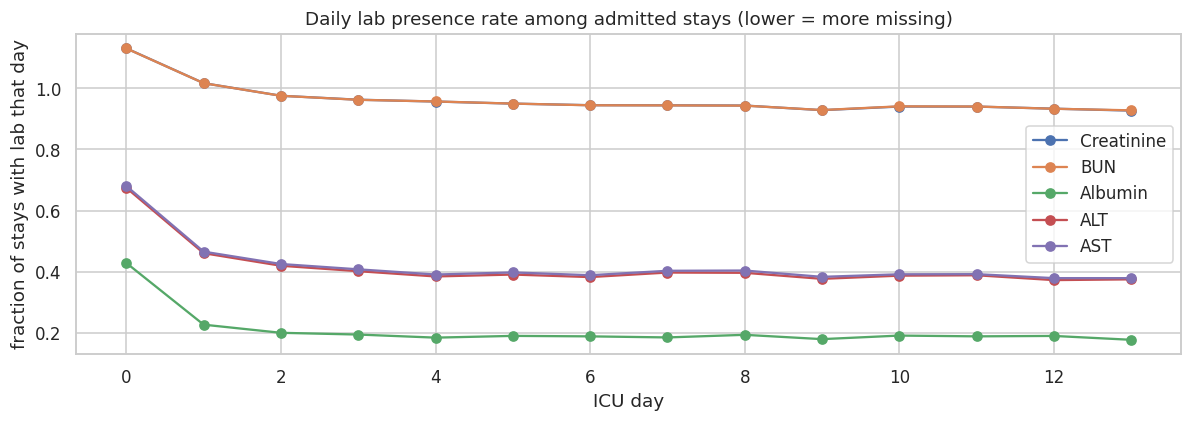

Albumin/ALT/AST show markedly lower and declining daily presence vs creatinine/BUN → time-dependent (non-random / MNAR-leaning) missingness, consistent with routine vs on-indication ordering.


In [43]:
# For each ICU day, fraction of still-present stays that have each lab that day
def daily_presence(lab_df, et, max_day=14):
    d = lab_df[(lab_df.event_type == et) & (lab_df.time_hours >= 0)]
    d = d.assign(day=(d.time_hours//24).astype(int))
    return d[d.day < max_day].groupby("day")["stay_id"].nunique()

# stays at risk per day (still admitted): approximate via los
los_days = (cov.los_icu_hrs//24).astype(int)
at_risk = pd.Series({day: (los_days >= day).sum() for day in range(14)})
plt.figure(figsize=(11, 4))
for et, c in zip([2, 3, 4, 5, 6],
                 ["C0", "C1", "C2", "C3", "C4"]):
    pres = daily_presence(labs, et)
    frac = (pres/at_risk).reindex(range(14)).fillna(0)
    plt.plot(frac.index, frac.values, "o-", color=c, label=EVENT_LABELS[et])
plt.title("Daily lab presence rate among admitted stays (lower = more missing)")
plt.xlabel("ICU day"); plt.ylabel("fraction of stays with lab that day")
plt.legend(); plt.tight_layout(); plt.show()
print("Albumin/ALT/AST show markedly lower and declining daily presence vs "
      "creatinine/BUN → time-dependent (non-random / MNAR-leaning) missingness, "
      "consistent with routine vs on-indication ordering.")

In [44]:
# Missingness by subject: distribution of per-stay completeness for body size
comp = cov_clean.assign(
    has_wt=cov_clean.weight_kg.notna(),
    has_ht=cov_clean.height_cm.notna())
print("Per-stay body-size completeness:")
print("  weight present:", comp.has_wt.mean().round(3))
print("  height present:", comp.has_ht.mean().round(3))
print("  both present  :", (comp.has_wt & comp.has_ht).mean().round(3))

Per-stay body-size completeness:
  weight present: 0.899
  height present: 0.614
  both present  : 0.594


## Key Takeaways for PK Modelling
#
1. **Log-scale everything PK.** Concentrations, doses, and all labs are
   strongly right-skewed / log-normal; both normality tests reject Gaussianity
   universally. Model on `log` and report MAPE / within-±20–30% accuracy
   (R²/RMSE are inappropriate here).
2. **Missingness is structured, not random.** Height (~39%) and albumin/ALT/AST
   show time-dependent, indication-driven missingness (MNAR-leaning) — the
   chi-square probe ties height-missing to sex/ventilation. Use principled
   imputation or missingness-aware encoders, never complete-case deletion.
3. **Outliers are mostly real physiology** (long stays, obese patients, renal
   support). They were flagged, never removed; handle with robust/log methods.
4. **Renal signal is the backbone.** Creatinine/BUN correlate with
   concentration and rank top in MI screening; CRRT/HD status materially shifts
   concentration distributions — central to clearance modelling.
5. **Referential gaps:** event tables contain stays absent from covariates;
   join on the intersection and document the coverage (done in §3).
6. **Dosing rhythm** clusters at 8/12/24h inter-dose intervals — usable as a
   structural prior for the dosing-event encoder.